<span style="font-size: 32px; font-weight: bold; color: #003366;">Proyecto Ausentismo en la administración pública de una provincia argentina</span>

<span style="font-size: 26px; font-weight: bold; color: #5ba6f1;">Equipo de trabajo Nro 15</span>
<ul>
  <li style="color: #81c6d2;"><b>Fabiana Winterstetter</b></li>
  <li style="color: #81c6d2;"><b>Nicolás Germán Diaz</b></li>
   
</ul>

El estudio de las pautas de ausentismo en las organizaciones públicas constituye un campo crítico dentro del análisis organizacional y la economía del trabajo. La disponibilidad de grandes volúmenes de datos transaccionales permite ir más allá del análisis estadístico descriptivo e incursionar en la modelación predictiva del comportamiento laboral.

Este trabajo final intenta abordar el ciclo completo de un proyecto de Data Science aplicado a la administración pública: 
<p style="font-size: 16px; line-height: 1.6;">
    <mark style="background-color: #e6f2ff; color: #003366; padding: 2px 5px; border-radius: 3px;">
    Desde la ingesta, limpieza e ingeniería de variables sobre datos reales de ausentismo, 
    hasta el entrenamiento y evaluación de algoritmos de clasificación.
    </mark>
</p>

<span style="font-size: 32px; font-weight: bold; color: #003366;">Variable Target</span>

Se realizó un análisis exhaustivo, el cual se puede ver en la notebook_analisis_dataset.

De este análisis exhaustivo decidimos definir como variable target y problema a resolver:

* __Predicción de Licencias por "Salud" o No Salud__

    * Problema: Predecir si una solicitud de ausencia iniciada en determinado día corresponderá a Salud / No salud.

    * Hallazgo del EDA: Artículos como Razones Particulares (14F) o Permisos Gremiales aumentan sensiblemente su concentración en lunes, viernes y días pre/post feriado (hasta un 53% se inician en esos días), a diferencia de licencias por afecciones prolongadas.

    * Features: es_lunes, es_viernes, es_pre_feriado, es_post_feriado, edad, antiguedad, escalafon, dependencia, es_invierno.

<span style="font-size: 24px; font-weight: bold; color: #003366;">1.Transformación de Datos</span>

<span style="font-size: 20px; font-weight: bold; color: #003366;">Importación de Librerías y Carga de Datos</span>


In [3]:
# 1. Manipulación y análisis de datos
import pandas as pd
import numpy as np

# 2. Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Gestión de advertencias
import warnings

# Mantener visibles las advertencias durante el desarrollo
warnings.filterwarnings("default")

# 4. Separación y preprocesamiento de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 5. Modelos de clasificación
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# 6. Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

pd.set_option('display.max_columns', None)

# 7. Configuración general de visualizaciones
sns.set_theme(style="whitegrid")

# Cargar el dataset con codificación latin1 y separador ';'
file_path = 'prueba2025_c.csv'
df_ausentismo = pd.read_csv(file_path, encoding='latin1', sep=';')

print(f"Dataset cargado correctamente: {df_ausentismo.shape[0]:,} filas y {df_ausentismo.shape[1]} columnas.")
df_ausentismo.head()


Dataset cargado correctamente: 949,038 filas y 16 columnas.


,nro_legajo,escalafon,categoria,cod_art_ausencia,descripcion_articulo_ausencia,es_de_salud,fecha_desde,fecha_hasta,cantidad_dias,cant_dias_permitido_mes,cantidad_dias_permitido_año,dependencia,anio_nacimiento,genero,antiguedad,remuneracion_mensual
0,28382130,3,852,1,10A-6IIIA ENF.COMUN,yes,5/6/2024,7/6/2024,3,0,45,138,1980,F,5,0.00
1,28382130,3,852,1,10A-6IIIA ENF.COMUN,yes,26/8/2024,27/8/2024,2,0,45,138,1980,F,5,0.00
2,28382130,3,852,1,10A-6IIIA ENF.COMUN,yes,7/10/2024,8/10/2024,2,0,45,138,1980,F,5,0.00
3,446214301,1,119,12,14F-6VD RAZONES PARTICULARES,no,27/3/2024,27/3/2024,1,2,7,620,1949,F,21,1530086.66
4,446214301,1,119,12,14F-6VD RAZONES PARTICULARES,no,19/4/2024,19/4/2024,1,2,7,620,1949,F,21,1530086.66


In [4]:

from pathlib import Path

archivo_knn = Path("resultados_knn_temporal.npz")

print("Carpeta de trabajo:")
print(Path.cwd())

print("\nArchivo temporal KNN disponible:")
print(archivo_knn.exists())

if archivo_knn.exists():
    import numpy as np

    with np.load(archivo_knn) as resultados:
        print("\nDatos guardados:")
        print(resultados.files)


Carpeta de trabajo:
c:\Users\gn_d4\Documents\GERMÁN\DATA SCIENCE\GitHub\python\PruebaAusentismo

Archivo temporal KNN disponible:
False


<span style="font-size: 20px; font-weight: bold; color: #003366;">Conversión y Limpieza de Fechas</span>


In [5]:
df_ausentismo['fecha_desde_dt'] = pd.to_datetime(df_ausentismo['fecha_desde'], format='%d/%m/%Y', errors='coerce')
df_ausentismo['edad_agente'] = df_ausentismo['fecha_desde_dt'].dt.year - df_ausentismo['anio_nacimiento']
df_ausentismo['mes_inicio'] = df_ausentismo['fecha_desde_dt'].dt.month
df_ausentismo['dia_semana_inicio_num'] = df_ausentismo['fecha_desde_dt'].dt.dayofweek

# Ordenar cronológicamente por legajo y fecha para garantizar cálculos de secuencias temporales correctos
df_ausentismo_ord = df_ausentismo.sort_values(['nro_legajo', 'fecha_desde']).reset_index(drop=True)

print("Conversión de fechas completada.")

print(df_ausentismo_ord.dtypes)

Conversión de fechas completada.
nro_legajo                                int64
escalafon                                 int64
categoria                                 int64
cod_art_ausencia                          int64
descripcion_articulo_ausencia               str
es_de_salud                                 str
fecha_desde                                 str
fecha_hasta                                 str
cantidad_dias                             int64
cant_dias_permitido_mes                   int64
cantidad_dias_permitido_año               int64
dependencia                               int64
anio_nacimiento                           int64
genero                                      str
antiguedad                                int64
remuneracion_mensual                    float64
fecha_desde_dt                   datetime64[us]
edad_agente                               int64
mes_inicio                                int32
dia_semana_inicio_num                     int32
dtype: 

<span style="font-size: 20px; font-weight: bold; color: #003366;">Feature Engineering - Limpieza temporal del dataset -Filtro adicional años</span>

In [6]:
# 1. Cantidad de registros antes de la limpieza
registros_originales = len(df_ausentismo_ord)

# 2. Distribución original por año de inicio
# Utilizamos fecha_desde_dt porque ya es datetime

print("DISTRIBUCIÓN ORIGINAL POR AÑO")

display(
    df_ausentismo_ord["fecha_desde_dt"]
    .dt.year
    .value_counts(dropna=False)
    .sort_index()
)

# 3. Verificar fechas faltantes
print("\nFECHAS DE INICIO FALTANTES:")
print(df_ausentismo_ord["fecha_desde_dt"].isna().sum())

# 4. Definir el período de estudio
fecha_inicio = pd.Timestamp("2024-01-01")
fecha_fin = pd.Timestamp("2026-01-01")

# 5. Crear la condición de filtrado
periodo_valido = (
    (df_ausentismo_ord["fecha_desde_dt"] >= fecha_inicio) &
    (df_ausentismo_ord["fecha_desde_dt"] < fecha_fin)
)

# 6. Guardar los registros excluidos
df_excluidos = df_ausentismo_ord.loc[
    ~periodo_valido
].copy()


# 7. Aplicar la limpieza al dataset principal
# Conservamos el nombre df_ausentismo_ord para continuar
# trabajando con el mismo DataFrame en todo el proyecto.

df_ausentismo_ord = (
    df_ausentismo_ord.loc[periodo_valido]
    .sort_values(["nro_legajo", "fecha_desde_dt"])
    .reset_index(drop=True)
    .copy()
)

# 8. Resumen de la limpieza

print("\nRESUMEN DE LA LIMPIEZA TEMPORAL")

print(f"Registros originales: {registros_originales:,}")
print(f"Registros excluidos: {len(df_excluidos):,}")
print(f"Registros conservados: {len(df_ausentismo_ord):,}")

porcentaje_excluido = (
    len(df_excluidos) / registros_originales * 100
)

print(f"Porcentaje excluido: {porcentaje_excluido:.4f}%")

# 9. Distribución final por año

print("\nDISTRIBUCIÓN FINAL POR AÑO")

display(
    df_ausentismo_ord["fecha_desde_dt"]
    .dt.year
    .value_counts()
    .sort_index()
)

# 10. Verificar el rango de fechas

print("\nRANGO DE FECHAS DE INICIO")

print("Fecha mínima:",
      df_ausentismo_ord["fecha_desde_dt"].min())

print("Fecha máxima:",
      df_ausentismo_ord["fecha_desde_dt"].max())

# 11. Revisar los registros excluidos

print("\nREGISTROS EXCLUIDOS")

display(
    df_excluidos[
        [
            "fecha_desde_dt",
            "fecha_hasta",
            "cantidad_dias",
            "descripcion_articulo_ausencia"
        ]
    ]
)

# 12. Validación final del dataset principal

assert df_ausentismo_ord["fecha_desde_dt"].dt.year.isin(
    [2024, 2025]
).all(), "Existen registros fuera del período de estudio"

assert len(df_ausentismo_ord) + len(df_excluidos) == (
    registros_originales
), "La cantidad de registros no coincide"

print("\nLIMPIEZA TEMPORAL VALIDADA CORRECTAMENTE")

print(f"Dimensiones finales: {df_ausentismo_ord.shape}")


DISTRIBUCIÓN ORIGINAL POR AÑO


fecha_desde_dt
2023         1
2024    463024
2025    486003
2026         9
2027         1
Name: count, dtype: int64


FECHAS DE INICIO FALTANTES:
0

RESUMEN DE LA LIMPIEZA TEMPORAL
Registros originales: 949,038
Registros excluidos: 11
Registros conservados: 949,027
Porcentaje excluido: 0.0012%

DISTRIBUCIÓN FINAL POR AÑO


fecha_desde_dt
2024    463024
2025    486003
Name: count, dtype: int64


RANGO DE FECHAS DE INICIO
Fecha mínima: 2024-01-01 00:00:00
Fecha máxima: 2025-12-31 00:00:00

REGISTROS EXCLUIDOS


,fecha_desde_dt,fecha_hasta,cantidad_dias,descripcion_articulo_ausencia
3759,2026-01-31,23/2/2026,24,REINICIO DE INTERRUPCIÓN DE LAR
46730,2026-02-13,25/2/2026,13,REINICIO DE INTERRUPCIÓN DE LAR
55238,2026-03-06,21/3/2026,16,REINICIO DE INTERRUPCIÓN DE LAR
91058,2026-01-29,14/2/2026,17,REINICIO DE INTERRUPCIÓN DE LAR
111973,2027-02-01,6/2/2027,6,REINICIO DE INTERRUPCIÓN DE LAR
111995,2026-11-20,26/11/2026,7,REINICIO DE INTERRUPCIÓN DE LAR
232382,2026-02-21,5/3/2026,13,REINICIO DE INTERRUPCIÓN DE LAR
386706,2026-06-02,11/6/2026,10,REINICIO DE INTERRUPCIÓN DE LAR
390486,2026-01-28,4/2/2026,8,REINICIO DE INTERRUPCIÓN DE LAR
481113,2023-11-21,21/11/2023,1,PERMISO GREMIAL



LIMPIEZA TEMPORAL VALIDADA CORRECTAMENTE
Dimensiones finales: (949027, 20)


"Reinicio de interrupción de LAR" significa que se reanuda el cómputo de las vacaciones (Licencia Anual Reglamentaria) de un empleado luego de que estas hubieran quedado pausadas por una causa justificada.
### Distribución final por año

| Año | Registros |
|---|---:|
| 2024 | 463.024 |
| 2025 | 486.003 |
| Total | 949.027 |

El período de análisis quedó comprendido entre el 1 de enero de 2024 y el 31 de diciembre de 2025.

### Limpieza temporal del dataset

La limpieza temporal permitió obtener un dataset de 949.027 registros correspondientes a los años 2024 y 2025.Esta modificación busca mejorar la consistencia temporal del análisis exploratorio y del posterior modelado de Machine Learning.

Aunque la proporción de registros excluidos es muy baja, la modificación evita interpretaciones incorrectas asociadas a períodos con escasa cobertura.


<span style="font-size: 20px; font-weight: bold; color: #003366;">Feature Engineering - Variables Temporales y Estacionalidad</span>


In [7]:

# Incorporación de Feriados y Días Sándwich (Tierra del Fuego)
feriados_2024_2025 = [
    '2024-01-01', '2024-02-12', '2024-02-13', '2024-03-24', '2024-03-28', '2024-03-29', 
    '2024-04-01', '2024-04-02', '2024-05-01', '2024-05-25', '2024-06-01', '2024-06-17', 
    '2024-06-20', '2024-06-21', '2024-07-09', '2024-08-17', '2024-10-11', '2024-10-12', 
    '2024-11-18', '2024-12-08', '2024-12-25',
    '2025-01-01', '2025-03-03', '2025-03-04', '2025-03-24', '2025-04-02', '2025-04-17', 
    '2025-04-18', '2025-05-01', '2025-05-02', '2025-05-25', '2025-06-01', '2025-06-16', 
    '2025-06-20', '2025-07-09', '2025-08-15', '2025-10-12', '2025-10-13', '2025-11-21', 
    '2025-11-24', '2025-12-08', '2025-12-25', '2025-12-26'
]
feriados_dt = pd.to_datetime(feriados_2024_2025)
dias_pre_feriado = feriados_dt - pd.Timedelta(days=1)
dias_post_feriado = feriados_dt + pd.Timedelta(days=1)

df_ausentismo_ord['es_feriado'] = df_ausentismo_ord['fecha_desde_dt'].isin(feriados_dt).astype(int)
df_ausentismo_ord['es_pre_feriado'] = df_ausentismo_ord['fecha_desde_dt'].isin(dias_pre_feriado).astype(int)
df_ausentismo_ord['es_post_feriado'] = df_ausentismo_ord['fecha_desde_dt'].isin(dias_post_feriado).astype(int)
df_ausentismo_ord['es_lunes'] = (df_ausentismo_ord['dia_semana_inicio_num'] == 0).astype(int)
df_ausentismo_ord['es_viernes'] = (df_ausentismo_ord['dia_semana_inicio_num'] == 4).astype(int)
df_ausentismo_ord['es_dia_sandwich'] = (df_ausentismo_ord['es_lunes'] | df_ausentismo_ord['es_viernes'] | df_ausentismo_ord['es_pre_feriado'] | df_ausentismo_ord['es_post_feriado']).astype(int)

# Crear el atributo 'es_invierno' 
# En el Hemisferio Sur, el invierno meteorológico comprende los meses de Junio (6), Julio (7) y Agosto (8)
df_ausentismo_ord['es_invierno'] = df_ausentismo_ord['mes_inicio'].isin([6, 7, 8]).map({True: 'sí', False: 'no'})

# Convertir a binario numérico (1 para sí, 0 para no)
df_ausentismo_ord['es_invierno_num'] = (df_ausentismo_ord['mes_inicio'].isin([6, 7, 8])).astype(int)

df_ausentismo_ord[['fecha_desde', 'es_feriado', 'es_pre_feriado', 'es_post_feriado', 'es_lunes', 'es_viernes', 'es_dia_sandwich', 'es_invierno_num']].head()





,fecha_desde,es_feriado,es_pre_feriado,es_post_feriado,es_lunes,es_viernes,es_dia_sandwich,es_invierno_num
0,5/6/2024,0,0,0,0,0,0,1
1,26/8/2024,0,0,0,1,0,1,1
2,7/10/2024,0,0,0,1,0,1,0
3,15/4/2025,0,0,0,0,0,0,0
4,28/4/2025,0,0,0,1,0,1,0


In [8]:
print("--- ESTADÍSTICAS DE CARACTERÍSTICAS TEMPORALES ---")
print("Total licencias en días sándwich / puente:", df_ausentismo_ord['es_dia_sandwich'].sum(), f"({df_ausentismo_ord['es_dia_sandwich'].mean()*100:.2f}%)")

print("\n--- DISTRIBUCIÓN POR DÍA DE LA SEMANA ---")
print(df_ausentismo_ord['fecha_desde_dt'].dt.day_name().value_counts())

--- ESTADÍSTICAS DE CARACTERÍSTICAS TEMPORALES ---
Total licencias en días sándwich / puente: 464076 (48.90%)

--- DISTRIBUCIÓN POR DÍA DE LA SEMANA ---
fecha_desde_dt
Monday       247153
Thursday     167309
Wednesday    163884
Tuesday      162678
Friday       146225
Saturday      36245
Sunday        25533
Name: count, dtype: int64


In [9]:
# Comparar ausencias de salud vs no salud en Sandwich(Puente) vs resto
print("Top artículos y su relación con Lunes/Viernes:")
top_10_arts = df_ausentismo_ord['descripcion_articulo_ausencia'].value_counts().head(10).index
ct = pd.crosstab(df_ausentismo_ord['descripcion_articulo_ausencia'], df_ausentismo_ord['es_dia_sandwich'], normalize='index') * 100
ct.columns = ['Resto de días (%)', 'Sandwich(Puente) (%)']
print(ct.loc[top_10_arts])

Top artículos y su relación con Lunes/Viernes:
                                     Resto de días (%)  Sandwich(Puente) (%)
descripcion_articulo_ausencia                                               
10A-6IIIA ENF.COMUN                          54.085928             45.914072
10J-6IIIH ENF. FAMILIAR                      52.656793             47.343207
14F-6VD RAZONES PARTICULARES                 39.730976             60.269024
FRANCO ROTATIVO                              62.243941             37.756059
PERMISO GREMIAL                              39.022145             60.977855
PARO POR DIA COMPLETO                        63.464020             36.535980
10C-6IIIB ENF. PROLONGADA                    62.323133             37.676867
PREVENCIÓN PERSONAL FEMENINO-564/18          50.104616             49.895384
POST-GUARDIA 24HS                            49.462604             50.537396
COM-COMISION DE SERVIC.DOC/AGTE.             57.942522             42.057478


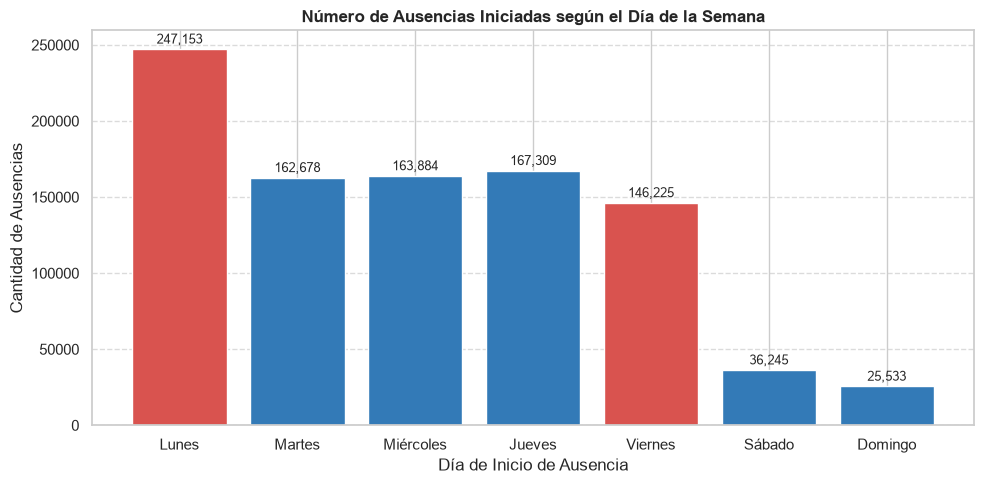

In [10]:
# Visualización de distribución por día de la semana
plt.figure(figsize=(10, 5))
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
days_translation = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

df_day = df_ausentismo_ord['fecha_desde_dt'].dt.day_name().value_counts().reindex(days_order)
colors = ['#d9534f' if d in ['Monday', 'Friday'] else '#337ab7' for d in days_order]

bars = plt.bar(days_translation, df_day.values, color=colors)
plt.title('Número de Ausencias Iniciadas según el Día de la Semana', fontsize=12, fontweight='bold')
plt.xlabel('Día de Inicio de Ausencia')
plt.ylabel('Cantidad de Ausencias')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2000, f'{int(yval):,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('dias_semana_ausencias.png', dpi=300)
plt.show()

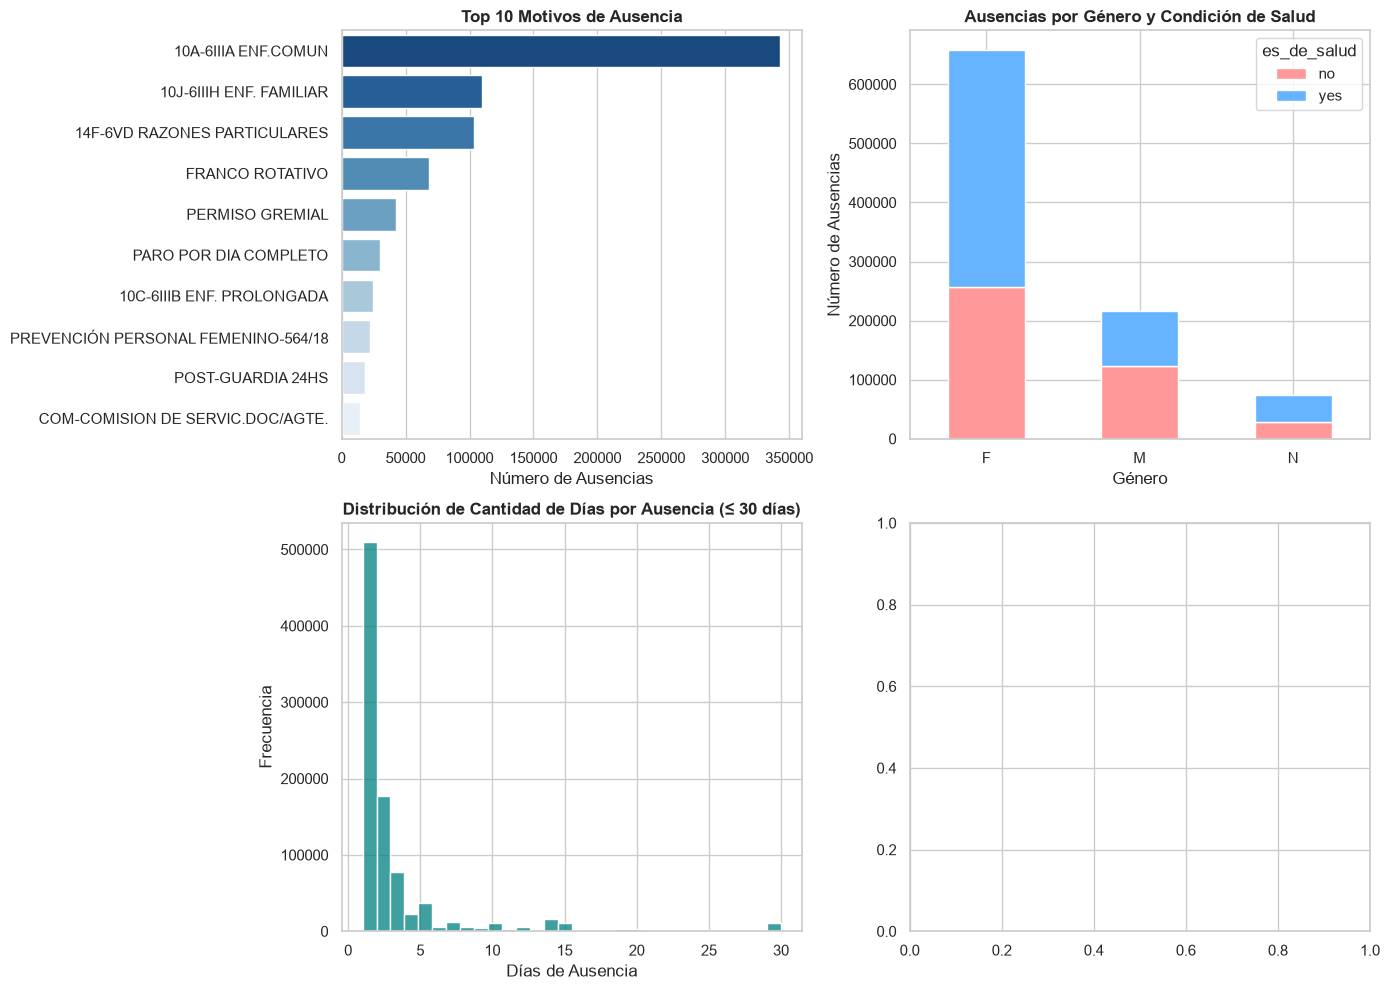

In [11]:
# Set style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

# Create figure with 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Top 10 Motivos de Ausencia
top_motivos = df_ausentismo_ord['descripcion_articulo_ausencia'].value_counts().head(10)
sns.barplot(x=top_motivos.values, y=top_motivos.index, hue=top_motivos.index,legend=False, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Top 10 Motivos de Ausencia", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Número de Ausencias")
axes[0, 0].set_ylabel("")

# 2. Distribución por Género y Salud
health_gender = df_ausentismo_ord.groupby(['genero', 'es_de_salud']).size().unstack(fill_value=0)
health_gender.plot(kind='bar', stacked=True, ax=axes[0, 1], color=['#ff9999','#66b3ff'])
axes[0, 1].set_title("Ausencias por Género y Condición de Salud", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Género")
axes[0, 1].set_ylabel("Número de Ausencias")
axes[0, 1].tick_params(axis='x', rotation=0)

# 3. Distribución de Cantidad de Días (hasta 30 días para mejor visualización)
sns.histplot(df_ausentismo_ord[df_ausentismo_ord['cantidad_dias'] <= 30]['cantidad_dias'], bins=30, kde=False, ax=axes[1, 0], color='teal')
axes[1, 0].set_title("Distribución de Cantidad de Días por Ausencia (≤ 30 días)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Días de Ausencia")
axes[1, 0].set_ylabel("Frecuencia")

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=300)
plt.show()

<span style="font-size: 20px; font-weight: bold; color: #003366;">Filtrar y etiquetar el target</span>


In [12]:
# ==================================================
# CONSTRUCCIÓN DE LA VARIABLE OBJETIVO
# ==================================================

# Clase 0: No Salud (Razones Particulares / Permisos Gremiales)
# Clase 1: Salud (Enfermedad común, atención familiar)
#articulos_salud = ['10A-6IIIA ENF.COMUN', '10J-6IIIH ENF. FAMILIAR', '10C-6IIIB ENF. PROLONGADA']
#articulos_particulares = ['14F-6VD RAZONES PARTICULARES', 'PERMISO GREMIAL', 'FRANCO ROTATIVO']

# 1. Validar los valores de la variable original
assert df_ausentismo_ord["es_de_salud"].isin(
    ["yes", "no"]
).all(), "Existen valores inesperados en es_de_salud"

# 2. Crear la variable objetivo
df_ausentismo_ord["target"] = (
    df_ausentismo_ord["es_de_salud"] == "yes"
).astype(int)

# 3. Analizar la distribución del target
distribucion_target = (
    df_ausentismo_ord["target"]
    .value_counts()
    .sort_index()
    .rename("cantidad_registros")
    .to_frame()
)

distribucion_target["porcentaje"] = (
    distribucion_target["cantidad_registros"]
    / len(df_ausentismo_ord) * 100
).round(2)

distribucion_target["clase"] = ["No Salud", "Salud"]

display(distribucion_target)

# 4. Validar la correspondencia entre las variables
display(
    pd.crosstab(
        df_ausentismo_ord["es_de_salud"],
        df_ausentismo_ord["target"]
    )
)

print("VARIABLE OBJETIVO VALIDADA CORRECTAMENTE")

,cantidad_registros,porcentaje,clase
target,,,
0,407430,42.93,No Salud
1,541597,57.07,Salud


target,0,1
es_de_salud,,
no,407430,0
yes,0,541597


VARIABLE OBJETIVO VALIDADA CORRECTAMENTE


<span style="font-size: 20px; font-weight: bold; color: #003366;">Definir Matriz de Características (Features) y Variable Objetivo</span>

Nota: Excluimos variables administrativas como los topes de días permitidos al mes/año para evitar la fuga de datos o "data leakage".

In [13]:
features = [
    "escalafon",
    "categoria",
    "dependencia",
    "antiguedad",
    "edad_agente",
    "mes_inicio",
    "dia_semana_inicio_num",
    "remuneracion_mensual",
    "es_feriado",
    "es_dia_sandwich",
    "es_invierno_num"
]


In [14]:

# ==================================================
# CLASIFICACIÓN DE VARIABLES PREDICTORAS
# ==================================================

# 1. Variables categóricas
# Se aplicará One-Hot Encoding

variables_categoricas = [
    "escalafon",
    "categoria",
    "dependencia"
]

# 2. Variables numéricas
# Se aplicará StandardScaler

variables_numericas = [
    "antiguedad",
    "edad_agente",
    "mes_inicio",
    "dia_semana_inicio_num",
    "remuneracion_mensual"
]

# 3. Variables binarias
# Se conservarán sin transformar

variables_binarias = [
    "es_feriado",
    "es_dia_sandwich",
    "es_invierno_num"
]

# 4. Validar que todas las variables estén clasificadas

variables_preprocesamiento = (
    variables_categoricas
    + variables_numericas
    + variables_binarias
)

assert set(variables_preprocesamiento) == set(features), (
    "Las variables clasificadas no coinciden con features"
)

# 5. Mostrar resultados

print("\nCLASIFICACIÓN DE VARIABLES")

print("Categóricas:", len(variables_categoricas))
print("Numéricas:", len(variables_numericas))
print("Binarias:", len(variables_binarias))

print("Total:", len(variables_preprocesamiento))

print("\nCLASIFICACIÓN VALIDADA CORRECTAMENTE")



CLASIFICACIÓN DE VARIABLES
Categóricas: 3
Numéricas: 5
Binarias: 3
Total: 11

CLASIFICACIÓN VALIDADA CORRECTAMENTE


<span style="font-size: 20px; font-weight: bold; color: #003366;">Division en train, test y escalado</span>

In [15]:
#Se cambaira esta celda usando otro escalador
#X = df_clasif_encoded
#y = df_clasif['target']


# División Train / Test (Estratificada para mantener proporciones)
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#escalador = StandardScaler()
#X_train_esc = escalador.fit_transform(X_train)
#X_test_esc = escalador.transform(X_test)

#print(f'Train: {X_train.shape[0]} filas — Test: {X_test.shape[0]} filas')
#print('Proporción de recurrencia en test:', round(y_test.mean(), 2))

In [16]:

# ==================================================
# DIVISIÓN TRAIN / TEST Y PREPROCESAMIENTO
# ==================================================

# 1. Preparar las variables predictoras y el target

df_clasif = (
    df_ausentismo_ord[features + ["target"]]
    .dropna()
    .copy()
)

X = df_clasif[features]
y = df_clasif["target"]

# 2. División Train / Test estratificada

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Preprocesamiento diferenciado por tipo de variable
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        ),
        (
            "binarias",
            "passthrough",
            variables_binarias
        )
    ],
    sparse_threshold=1.0,
    remainder="drop"
)

# 4. Ajustar el preprocesamiento con entrenamiento

X_train_esc = preprocesador.fit_transform(X_train)

# 5. Aplicar el mismo preprocesamiento a prueba

X_test_esc = preprocesador.transform(X_test)

# 6. Mostrar resultados

print("DIMENSIONES DEL MODELADO")

print(f"Train: {X_train.shape[0]} filas")
print(f"Test: {X_test.shape[0]} filas")

print("\nAntes del preprocesamiento:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nDespués del preprocesamiento:")
print("X_train_esc:", X_train_esc.shape)
print("X_test_esc:", X_test_esc.shape)

print("\nProporción de Salud en test:",
      round(y_test.mean(), 4))

print("\nTipo de matriz:")
print(type(X_train_esc))

print("\nPREPROCESAMIENTO FINALIZADO")

DIMENSIONES DEL MODELADO
Train: 759221 filas
Test: 189806 filas

Antes del preprocesamiento:
X_train: (759221, 11)
X_test: (189806, 11)

Después del preprocesamiento:
X_train_esc: (759221, 696)
X_test_esc: (189806, 696)

Proporción de Salud en test: 0.5707

Tipo de matriz:
<class 'scipy.sparse._csr.csr_matrix'>

PREPROCESAMIENTO FINALIZADO


In [17]:

# ==================================================
# VALIDACIÓN DEL ONE-HOT ENCODING
# ==================================================

encoder = preprocesador.named_transformers_["categoricas"]

for variable, categorias in zip(
    variables_categoricas,
    encoder.categories_
):
    print(f"{variable}: {len(categorias)} categorías")

print("\nTotal de columnas categóricas:",
      sum(len(c) for c in encoder.categories_))

print("Total de columnas transformadas:",
      len(preprocesador.get_feature_names_out()))


escalafon: 8 categorías
categoria: 233 categorías
dependencia: 447 categorías

Total de columnas categóricas: 688
Total de columnas transformadas: 696


In [18]:

# ==================================================
# ESTUDIO DE ABLACIÓN - PREPARACIÓN DEL EXPERIMENTO
# ==================================================

# Dividir únicamente el conjunto de entrenamiento
# Conservamos X_test e y_test para la evaluación final

X_train_exp, X_val_exp, y_train_exp, y_val_exp = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Verificar las dimensiones

print("DIMENSIONES DEL EXPERIMENTO")

print(f"Entrenamiento: {X_train_exp.shape}")
print(f"Validación: {X_val_exp.shape}")
print(f"Test reservado: {X_test.shape}")

# Verificar la distribución del target

print("\nPROPORCIÓN DE SALUD")

print(f"Entrenamiento: {y_train_exp.mean():.4f}")
print(f"Validación: {y_val_exp.mean():.4f}")
print(f"Test: {y_test.mean():.4f}")

# Validar que no se pierdan registros

assert len(X_train_exp) + len(X_val_exp) == len(X_train)

print("\nDIVISIÓN DEL EXPERIMENTO VALIDADA")


DIMENSIONES DEL EXPERIMENTO
Entrenamiento: (607376, 11)
Validación: (151845, 11)
Test reservado: (189806, 11)

PROPORCIÓN DE SALUD
Entrenamiento: 0.5707
Validación: 0.5707
Test: 0.5707

DIVISIÓN DEL EXPERIMENTO VALIDADA


In [19]:

# ==================================================
# ESTUDIO DE ABLACIÓN - MODELO A CON REMUNERACIÓN
# ==================================================

# 1. Crear un preprocesador exclusivo del experimento

preprocesador_con_remuneracion = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        ),
        (
            "binarias",
            "passthrough",
            variables_binarias
        )
    ],
    sparse_threshold=1.0,
    remainder="drop"
)

# 2. Ajustar únicamente con los datos de entrenamiento

X_train_con_rem = preprocesador_con_remuneracion.fit_transform(
    X_train_exp
)

X_val_con_rem = preprocesador_con_remuneracion.transform(
    X_val_exp
)

# 3. Entrenar el modelo de Regresión Logística

modelo_lr_con_rem = LogisticRegression(
    max_iter=3000,
    random_state=42
)

modelo_lr_con_rem.fit(
    X_train_con_rem,
    y_train_exp
)

# 4. Generar predicciones sobre validación

y_pred_con_rem = modelo_lr_con_rem.predict(
    X_val_con_rem
)

y_prob_con_rem = modelo_lr_con_rem.predict_proba(
    X_val_con_rem
)[:, 1]

# 5. Calcular las métricas

resultados_con_rem = {
    "Modelo": "Con remuneración",
    "Accuracy": accuracy_score(y_val_exp, y_pred_con_rem),
    "Precision": precision_score(y_val_exp, y_pred_con_rem),
    "Recall": recall_score(y_val_exp, y_pred_con_rem),
    "F1": f1_score(y_val_exp, y_pred_con_rem),
    "ROC-AUC": roc_auc_score(y_val_exp, y_prob_con_rem)
}

# 6. Mostrar los resultados

print("MODELO A - CON REMUNERACIÓN")

print("\nDimensiones después del preprocesamiento:")
print("Entrenamiento:", X_train_con_rem.shape)
print("Validación:", X_val_con_rem.shape)

print("\nMÉTRICAS DEL MODELO")

display(
    pd.DataFrame([resultados_con_rem]).round(4)
)

print("\nMODELO A ENTRENADO Y EVALUADO CORRECTAMENTE")


MODELO A - CON REMUNERACIÓN

Dimensiones después del preprocesamiento:
Entrenamiento: (607376, 695)
Validación: (151845, 695)

MÉTRICAS DEL MODELO


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Con remuneración,0.7989,0.7939,0.8747,0.8324,0.8742



MODELO A ENTRENADO Y EVALUADO CORRECTAMENTE


In [20]:

# ==================================================
# ESTUDIO DE ABLACIÓN - MODELO B SIN REMUNERACIÓN
# ==================================================

# 1. Definir las variables sin remuneración

features_sin_rem = [
    variable for variable in features
    if variable != "remuneracion_mensual"
]

variables_numericas_sin_rem = [
    variable for variable in variables_numericas
    if variable != "remuneracion_mensual"
]

# Validar la cantidad de variables

assert len(features_sin_rem) == 10

# 2. Crear un preprocesador exclusivo para el Modelo B

preprocesador_sin_remuneracion = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas_sin_rem
        ),
        (
            "binarias",
            "passthrough",
            variables_binarias
        )
    ],
    sparse_threshold=1.0,
    remainder="drop"
)

# 3. Preprocesar los mismos registros del Modelo A

X_train_sin_rem = preprocesador_sin_remuneracion.fit_transform(
    X_train_exp[features_sin_rem]
)

X_val_sin_rem = preprocesador_sin_remuneracion.transform(
    X_val_exp[features_sin_rem]
)

# 4. Entrenar Regresión Logística

modelo_lr_sin_rem = LogisticRegression(
    max_iter=3000,
    random_state=42
)

modelo_lr_sin_rem.fit(
    X_train_sin_rem,
    y_train_exp
)

# 5. Generar predicciones sobre validación

y_pred_sin_rem = modelo_lr_sin_rem.predict(
    X_val_sin_rem
)

y_prob_sin_rem = modelo_lr_sin_rem.predict_proba(
    X_val_sin_rem
)[:, 1]

# 6. Calcular las métricas

resultados_sin_rem = {
    "Modelo": "Sin remuneración",
    "Accuracy": accuracy_score(y_val_exp, y_pred_sin_rem),
    "Precision": precision_score(y_val_exp, y_pred_sin_rem),
    "Recall": recall_score(y_val_exp, y_pred_sin_rem),
    "F1": f1_score(y_val_exp, y_pred_sin_rem),
    "ROC-AUC": roc_auc_score(y_val_exp, y_prob_sin_rem)
}

# 7. Mostrar resultados

print("MODELO B - SIN REMUNERACIÓN")

print("\nDimensiones después del preprocesamiento:")
print("Entrenamiento:", X_train_sin_rem.shape)
print("Validación:", X_val_sin_rem.shape)

print("\nMÉTRICAS DEL MODELO")

display(
    pd.DataFrame([resultados_sin_rem]).round(4)
)

print("\nMODELO B ENTRENADO Y EVALUADO CORRECTAMENTE")


MODELO B - SIN REMUNERACIÓN

Dimensiones después del preprocesamiento:
Entrenamiento: (607376, 694)
Validación: (151845, 694)

MÉTRICAS DEL MODELO


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Sin remuneración,0.7958,0.7829,0.8887,0.8324,0.8495



MODELO B ENTRENADO Y EVALUADO CORRECTAMENTE


COMPARACIÓN DE MODELOS - ESTUDIO DE ABLACIÓN


Modelo,Con remuneración,Sin remuneración,Diferencia A - B
Accuracy,0.7989,0.7958,0.0031
Precision,0.7939,0.7829,0.0110
Recall,0.8747,0.8887,-0.0140
F1,0.8324,0.8324,-0.0001
ROC-AUC,0.8742,0.8495,0.0247


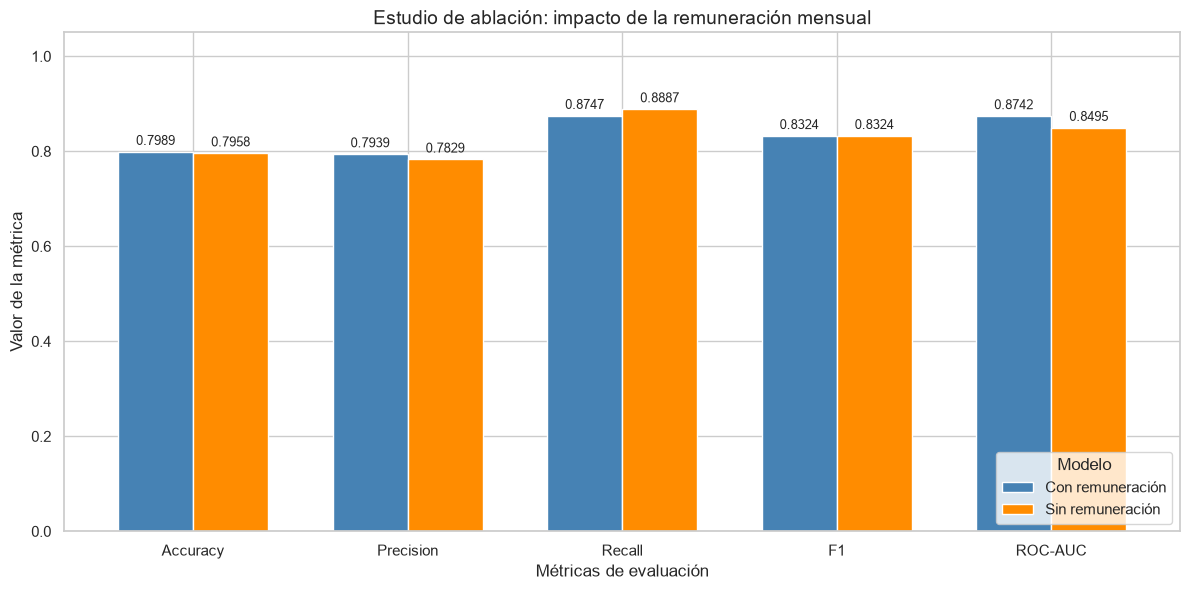

In [21]:

# ==================================================
# ESTUDIO DE ABLACIÓN - COMPARACIÓN DE RESULTADOS
# ==================================================

# 1. Consolidar los resultados de ambos modelos

df_ablacion = pd.DataFrame([
    resultados_con_rem,
    resultados_sin_rem
]).set_index("Modelo")

# 2. Construir tabla comparativa

comparacion_ablacion = df_ablacion.T.copy()

comparacion_ablacion["Diferencia A - B"] = (
    comparacion_ablacion["Con remuneración"]
    - comparacion_ablacion["Sin remuneración"]
)

print("COMPARACIÓN DE MODELOS - ESTUDIO DE ABLACIÓN")

display(comparacion_ablacion.round(4))

# 3. Visualizar las métricas

ax = df_ablacion.T.plot(
    kind="bar",
    figsize=(12, 6),
    color=["steelblue", "darkorange"],
    width=0.7
)

ax.set_title(
    "Estudio de ablación: impacto de la remuneración mensual",
    fontsize=14
)

ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("Métricas de evaluación")
ax.set_ylim(0, 1.05)

plt.xticks(rotation=0)

# Mostrar los valores encima de las barras

for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

plt.legend(title="Modelo", loc="lower right")
plt.tight_layout()
plt.show()


<span style="font-size: 20px; font-weight: bold; color: #003366;">Ajuste de modelos de clasificacion</span>

Entrenamos cuatro modelos sobre los datos ya escalados:
- **Regresion Logistica**
- **K Nearest Neighbors** (con k=5)
- **Support Vector Machine** (con kernel RBF)
- **Random Forest**

<span style="font-size: 16px; font-weight: bold; color: #003366;">Regresión Logística</span>

In [22]:
modelo_logistica = LogisticRegression(max_iter=3000)
modelo_logistica.fit(X_train_esc, y_train)
y_pred_logistica = modelo_logistica.predict(X_test_esc)


<span style="font-size: 16px; font-weight: bold; color: #003366;">Matriz de confusion del modelo de Regresion Logistica</span>

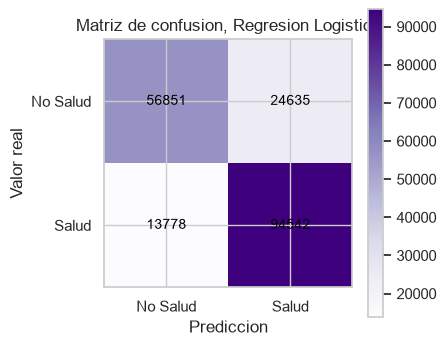

In [23]:
predicciones_logistica = modelo_logistica.predict(X_test_esc)
matriz_confusion = confusion_matrix(y_test, predicciones_logistica)

plt.figure(figsize=(4, 4))
plt.imshow(matriz_confusion, cmap='Purples')
plt.title('Matriz de confusion, Regresion Logistica')
plt.xlabel('Prediccion')
plt.ylabel('Valor real')
plt.xticks([0, 1], ['No Salud', 'Salud'])
plt.yticks([0, 1], ['No Salud', 'Salud'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz_confusion[i, j], ha='center', va='center', color='black')
plt.colorbar()
plt.show()


#cm = confusion_matrix(y_test, y_pred_clf)
#disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Art Salud', 'Art Particular'])
#disp.plot(cmap='Purples', colorbar=False)
#plt.title('Matriz de confusión')
#plt.show()

<span style="font-size: 16px; font-weight: bold; color: #003366;">K Nearest Neighbors (con k=5)</span>

In [24]:

# ==================================================
# KNN (K-NEAREST NEIGHBORS)
# EJECUCIÓN CON GUARDADO TEMPORAL DE RESULTADOS
# ==================================================

import time
import numpy as np

from pathlib import Path
from sklearn.neighbors import KNeighborsClassifier

# 1. Configurar archivo temporal

archivo_knn = Path("resultados_knn_temporal.npz")

inicio = time.time()

# ==================================================
# 2. RECUPERAR RESULTADOS SI YA EXISTEN
# ==================================================

if archivo_knn.exists():

    print("Recuperando resultados KNN guardados...")

    with np.load(archivo_knn) as resultados:

        # Validar que el conjunto de Test no cambió

        assert np.array_equal(
            resultados["indices_test"],
            X_test.index.to_numpy()
        ), "El conjunto de Test cambió"

        assert np.array_equal(
            resultados["y_test"],
            np.asarray(y_test)
        ), "Los valores de y_test cambiaron"

        # Validar el conjunto de entrenamiento

        assert np.array_equal(
            resultados["indices_train"],
            X_train.index.to_numpy()
        ), "El conjunto de Train cambió"

        assert np.array_equal(
            resultados["y_train"],
            np.asarray(y_train)
        ), "Los valores de y_train cambiaron"

        # Recuperar predicciones y probabilidades

        y_pred_knn = resultados["y_pred_knn"]

        y_prob_knn = resultados["y_prob_knn"]

    print("Resultados recuperados correctamente.")

# ==================================================
# 3. CALCULAR KNN SI EL ARCHIVO NO EXISTE
# ==================================================

else:

    print("No existen resultados guardados.")
    print("Entrenando modelo KNN...")

    modelo_knn = KNeighborsClassifier(
        n_neighbors=5
    )

    modelo_knn.fit(X_train_esc, y_train)

    print("Modelo entrenado.")
    print("Calculando probabilidades y predicciones...")
    print("Esta operación puede demorar 45 minutos aprox.")

    # Calcular probabilidades UNA SOLA VEZ

    probabilidades_knn = modelo_knn.predict_proba(
        X_test_esc
    )

    # Obtener probabilidades de la clase Salud (1)

    y_prob_knn = probabilidades_knn[:, 1]

    # Obtener predicciones sin repetir la búsqueda
    # de vecinos

    y_pred_knn = modelo_knn.classes_[
        np.argmax(probabilidades_knn, axis=1)
    ]

    # Guardar resultados automáticamente

    np.savez_compressed(
        archivo_knn,
        y_pred_knn=y_pred_knn,
        y_prob_knn=y_prob_knn,
        y_test=np.asarray(y_test),
        y_train=np.asarray(y_train),
        indices_test=X_test.index.to_numpy(),
        indices_train=X_train.index.to_numpy()
    )

    print("\nResultados KNN guardados correctamente.")
    print("Archivo:", archivo_knn.resolve())

# ==================================================
# 4. CALCULAR MÉTRICAS DE EVALUACIÓN
# ==================================================

accuracy_knn = accuracy_score(y_test, y_pred_knn)

precision_knn = precision_score(y_test, y_pred_knn)

recall_knn = recall_score(y_test, y_pred_knn)

f1_knn = f1_score(y_test, y_pred_knn)

auc_knn = roc_auc_score(y_test, y_prob_knn)

# ==================================================
# 5. MOSTRAR RESULTADOS
# ==================================================

print("\nRESULTADOS KNN (k=5)")
print("-" * 40)

print(f"Accuracy:  {accuracy_knn:.6f}")
print(f"Precision: {precision_knn:.6f}")
print(f"Recall:    {recall_knn:.6f}")
print(f"F1 Score:  {f1_knn:.6f}")
print(f"ROC-AUC:   {auc_knn:.6f}")

print("-" * 40)

print(f"Registros evaluados: {len(y_pred_knn):,}")

# Calcular tiempo de ejecución

fin = time.time()

tiempo_total = fin - inicio

minutos = int(tiempo_total // 60)
segundos = tiempo_total % 60

print(
    f"Tiempo de ejecución: "
    f"{minutos} minutos y {segundos:.2f} segundos"
)



No existen resultados guardados.
Entrenando modelo KNN...
Modelo entrenado.
Calculando probabilidades y predicciones...
Esta operación puede demorar 45 minutos aprox.

Resultados KNN guardados correctamente.
Archivo: C:\Users\gn_d4\Documents\GERMÁN\DATA SCIENCE\GitHub\python\PruebaAusentismo\resultados_knn_temporal.npz

RESULTADOS KNN (k=5)
----------------------------------------
Accuracy:  0.830290
Precision: 0.850321
Recall:    0.852723
F1 Score:  0.851521
ROC-AUC:   0.894604
----------------------------------------
Registros evaluados: 189,806
Tiempo de ejecución: 38 minutos y 44.63 segundos


In [25]:

# ==================================================
# KNN - GUARDAR RESULTADOS TEMPORALES
# ==================================================

import numpy as np

# 1. Calcular probabilidades para la curva ROC
# IMPORTANTE: esta operación también puede demorar

y_prob_knn = modelo_knn.predict_proba(X_test_esc)[:, 1]

# 2. Calcular métricas

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
auc_knn = roc_auc_score(y_test, y_prob_knn)

# 3. Guardar resultados en un archivo

np.savez_compressed(
    "resultados_knn_temporal.npz",
    y_pred_knn=y_pred_knn,
    y_prob_knn=y_prob_knn,
    y_test=np.asarray(y_test),
    indices_test=X_test.index.to_numpy(),
    accuracy=accuracy_knn,
    precision=precision_knn,
    recall=recall_knn,
    f1=f1_knn,
    auc=auc_knn
)

# 4. Mostrar métricas calculadas

print("RESULTADOS KNN GUARDADOS")

print(f"Accuracy:  {accuracy_knn:.6f}")
print(f"Precision: {precision_knn:.6f}")
print(f"Recall:    {recall_knn:.6f}")
print(f"F1 Score:  {f1_knn:.6f}")
print(f"ROC-AUC:   {auc_knn:.6f}")

print("\nArchivo: resultados_knn_temporal.npz")


RESULTADOS KNN GUARDADOS
Accuracy:  0.830290
Precision: 0.850321
Recall:    0.852723
F1 Score:  0.851521
ROC-AUC:   0.894604

Archivo: resultados_knn_temporal.npz


<span style="font-size: 16px; font-weight: bold; color: #003366;">Support Vector Machine(con kernel RBF)</span>

In [26]:
#No realizamos esta celda por tardar mucho tiempo en generarse
#modelo_svm = SVC(kernel='rbf', random_state=42)
#modelo_svm.fit(X_train_esc, y_train)
#y_pred_svm=modelo_svm.predict(X_test_esc)

#La vamos a modificar por un calculo de métricas con 15.000 registros

# ==================================================
# MODELO SVM - ENTRENAMIENTO CON MUESTRA
# ==================================================

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Seleccionar una muestra de entrenamiento

X_train_svm, _, y_train_svm, _ = train_test_split(
    X_train_esc,
    y_train,
    train_size=15000,
    random_state=42,
    stratify=y_train
)

# 2. Seleccionar una muestra de Test

X_test_svm, _, y_test_svm, _ = train_test_split(
    X_test_esc,
    y_test,
    train_size=15000,
    random_state=42,
    stratify=y_test
)

# 3. Crear el modelo SVM

modelo_svm = SVC(
    kernel="rbf",
    random_state=42
)

# 4. Entrenar el modelo

modelo_svm.fit(X_train_svm, y_train_svm)

# 5. Generar predicciones

y_pred_svm = modelo_svm.predict(X_test_svm)

# 6. Calcular las métricas

accuracy = accuracy_score(y_test_svm, y_pred_svm)
precision = precision_score(y_test_svm, y_pred_svm)
recall = recall_score(y_test_svm, y_pred_svm)
f1 = f1_score(y_test_svm, y_pred_svm)

# 7. Mostrar resultados

print("MODELO SVM - KERNEL RBF")

print(f"\nRegistros de entrenamiento: {X_train_svm.shape[0]}")
print(f"Registros de evaluación: {X_test_svm.shape[0]}")

print("\nMÉTRICAS DEL MODELO")

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")



MODELO SVM - KERNEL RBF

Registros de entrenamiento: 15000
Registros de evaluación: 15000

MÉTRICAS DEL MODELO
Accuracy: 0.7981
Precision: 0.7889
Recall: 0.8821
F1 Score: 0.8329


***Nota:*** *tardó unas 8 horas en generar este modelo con la totalidad de registros del dataset*

<span style="font-size: 16px; font-weight: bold; color: #003366;">Random Forest</span>

In [27]:
modelo_rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train_esc, y_train)
y_pred_rf = modelo_rf.predict(X_test_esc)

<span style="font-size: 16px; font-weight: bold; color: #003366;">Gráfico de Importancia de Variables (Feature Importance)</span>

Columnas transformadas: 696
Importancias del modelo: 696

Variables originales: 11
Suma de importancias: 1.0

IMPORTANCIA DE VARIABLES - RANDOM FOREST


,Importancia,Porcentaje
Variable,,
escalafon,0.3529,35.2866
remuneracion_mensual,0.2712,27.1184
categoria,0.1991,19.9147
dependencia,0.1271,12.7121
antiguedad,0.0164,1.6446
mes_inicio,0.0126,1.2622
edad_agente,0.0088,0.8831
dia_semana_inicio_num,0.0064,0.6385
es_dia_sandwich,0.0042,0.4186


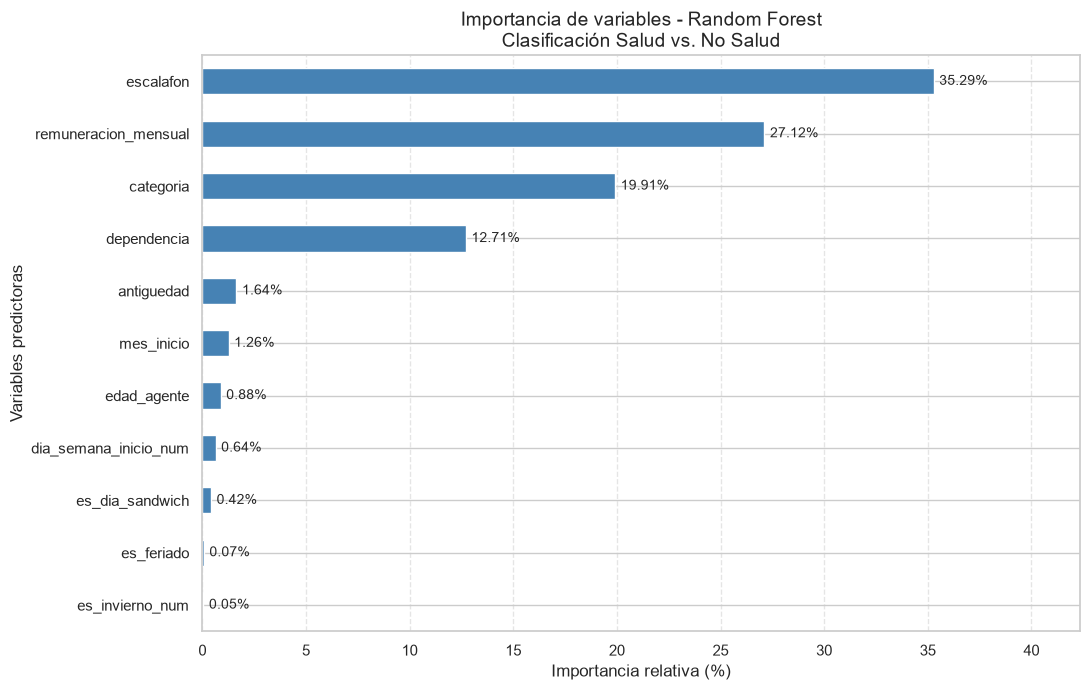


IMPORTANCIA DE VARIABLES VALIDADA CORRECTAMENTE


In [28]:

# ==================================================
# RANDOM FOREST - IMPORTANCIA DE VARIABLES AGRUPADAS
# ==================================================

# 1. Obtener los nombres de las columnas transformadas

nombres_features = preprocesador.get_feature_names_out()

# 2. Obtener las importancias del modelo Random Forest

importancias_rf = modelo_rf.feature_importances_

# 3. Validar que las dimensiones coincidan

assert len(nombres_features) == len(importancias_rf), (
    "Las columnas transformadas no coinciden "
    "con las importancias del modelo"
)

print("Columnas transformadas:", len(nombres_features))
print("Importancias del modelo:", len(importancias_rf))

# 4. Crear una tabla con las importancias individuales

df_importancias = pd.DataFrame({
    "Feature_transformada": nombres_features,
    "Importancia": importancias_rf
})

# 5. Agrupar las importancias por variable original

importancias_agrupadas = {}

# Variables categóricas: sumar todas sus categorías

for variable in variables_categoricas:

    prefijo = f"categoricas__{variable}_"

    mascara = df_importancias[
        "Feature_transformada"
    ].str.startswith(prefijo)

    importancias_agrupadas[variable] = (
        df_importancias.loc[mascara, "Importancia"].sum()
    )

# Variables numéricas: conservar su importancia

for variable in variables_numericas:

    nombre = f"numericas__{variable}"

    mascara = (
        df_importancias["Feature_transformada"] == nombre
    )

    importancias_agrupadas[variable] = (
        df_importancias.loc[mascara, "Importancia"].sum()
    )

# Variables binarias: conservar su importancia

for variable in variables_binarias:

    nombre = f"binarias__{variable}"

    mascara = (
        df_importancias["Feature_transformada"] == nombre
    )

    importancias_agrupadas[variable] = (
        df_importancias.loc[mascara, "Importancia"].sum()
    )

# 6. Construir la tabla final

df_importancias_agrupadas = (
    pd.DataFrame.from_dict(
        importancias_agrupadas,
        orient="index",
        columns=["Importancia"]
    )
    .sort_values("Importancia", ascending=False)
)

df_importancias_agrupadas.index.name = "Variable"

df_importancias_agrupadas["Porcentaje"] = (
    df_importancias_agrupadas["Importancia"] * 100
)

# 7. Validar las importancias agrupadas

assert len(df_importancias_agrupadas) == len(features)

assert np.isclose(
    df_importancias_agrupadas["Importancia"].sum(),
    importancias_rf.sum()
), "La suma de importancias no coincide"

print("\nVariables originales:", len(df_importancias_agrupadas))

print(
    "Suma de importancias:",
    round(df_importancias_agrupadas["Importancia"].sum(), 4)
)

print("\nIMPORTANCIA DE VARIABLES - RANDOM FOREST")

display(df_importancias_agrupadas.round(4))

# 8. Graficar las importancias agrupadas

df_grafico = df_importancias_agrupadas.sort_values(
    "Porcentaje",
    ascending=True
)

ax = df_grafico["Porcentaje"].plot(
    kind="barh",
    figsize=(11, 7),
    color="steelblue"
)

ax.set_title(
    "Importancia de variables - Random Forest\n"
    "Clasificación Salud vs. No Salud",
    fontsize=14
)

ax.set_xlabel("Importancia relativa (%)")
ax.set_ylabel("Variables predictoras")

# Mostrar el porcentaje de cada variable

for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.2f%%",
        padding=4
    )

ax.set_xlim(
    0,
    df_grafico["Porcentaje"].max() * 1.20
)

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("\nIMPORTANCIA DE VARIABLES VALIDADA CORRECTAMENTE")


<span style="font-size: 20px; font-weight: bold; color: #003366;">Evaluacion y comparacion de modelos</span>

In [33]:

# 1. Utilizar las predicciones previamente calculadas
# Evitamos volver a ejecutar predict() en KNN

predicciones_modelos = {
    "Regresión Logística": y_pred_logistica,
    "KNN (k=5)": y_pred_knn,
    "Random Forest": y_pred_rf
    #'SVM con kernel RBF': modelo_svm
}

# 2. Calcular las métricas de cada modelo

resultados_clasificacion = []

for nombre, predicciones in predicciones_modelos.items():

    # Validar que las predicciones correspondan al Test

    assert len(predicciones) == len(y_test), (
        f"Las predicciones de {nombre} "
        "no coinciden con el conjunto de Test"
    )

    resultados_clasificacion.append({
        "Modelo": nombre,
        "Registros evaluados": len(y_test),
        "Accuracy": accuracy_score(y_test, predicciones),
        "Precision": precision_score(y_test, predicciones),
        "Recall": recall_score(y_test, predicciones),
        "F1": f1_score(y_test, predicciones)
    })

# 3. Construir la tabla de resultados

df_resultados_clasificacion = pd.DataFrame(
    resultados_clasificacion
)

# 4. Ordenar por F1-Score

df_resultados_clasificacion = (
    df_resultados_clasificacion
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

# 5. Mostrar los resultados

print("COMPARACIÓN DE MODELOS - TEST COMPLETO")

display(df_resultados_clasificacion.round(4))




COMPARACIÓN DE MODELOS - TEST COMPLETO


,Modelo,Registros evaluados,Accuracy,Precision,Recall,F1
0,KNN (k=5),189806,0.8303,0.8503,0.8527,0.8515
1,Random Forest,189806,0.7943,0.7781,0.8947,0.8323
2,Regresión Logística,189806,0.7976,0.7933,0.8728,0.8311


Plot generated successfully.


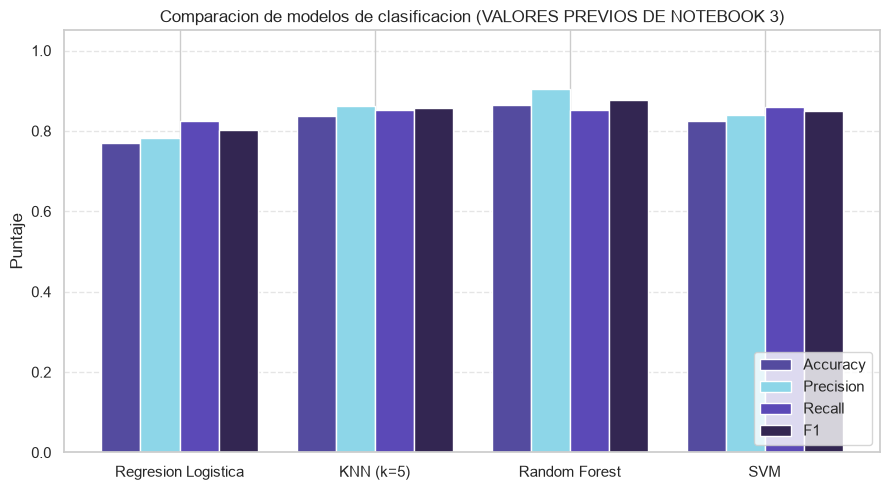

In [ ]:
# COMPARACIÓN DE MODELOS DE CLASIFICACIÓN
# RESULTADOS HISTÓRICOS - NOTEBOOK 3

# Simulating df_resultados_clasificacion based on user's loop structure
data = [
    {'Modelo': 'Regresion Logistica', 'Accuracy': 0.769752, 'Precision': 0.783132, 'Recall': 0.825000, 'F1': 0.803521},
    {'Modelo': 'KNN (k=5)', 'Accuracy': 0.837773, 'Precision': 0.862823, 'Recall': 0.851034, 'F1': 0.856888},
    {'Modelo': 'Random Forest', 'Accuracy': 0.864321, 'Precision': 0.903920, 'Recall': 0.852908, 'F1': 0.877674},
    {'Modelo': 'SVM', 'Accuracy': 0.825545, 'Precision': 0.838718, 'Recall': 0.859601, 'F1': 0.849031}  
]
df_resultados_notebook3 = pd.DataFrame(data)

# Code for grouped bar chart matching user's request
plt.figure(figsize=(9, 5))
x = np.arange(len(df_resultados_notebook3['Modelo']))
width = 0.2

plt.bar(x - 1.5*width, df_resultados_notebook3['Accuracy'], width, label='Accuracy', color='#544B9F')
plt.bar(x - 0.5*width, df_resultados_notebook3['Precision'], width, label='Precision', color='#8DD6E8')
plt.bar(x + 0.5*width, df_resultados_notebook3['Recall'], width, label='Recall', color="#5B49B7")
plt.bar(x + 1.5*width, df_resultados_notebook3['F1'], width, label='F1', color="#332652")

plt.ylabel('Puntaje')
plt.title('Comparacion de modelos de clasificacion (VALORES PREVIOS DE NOTEBOOK 3)')
plt.xticks(x, df_resultados_notebook3['Modelo'])
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('comparativa_modelos_personalizada.png')
print("Plot generated successfully.")


In [36]:
# ==================================================
# VALIDACIÓN DE RESULTADOS HISTÓRICOS Y ACTUALES
# ==================================================

print("RESULTADOS NOTEBOOK 3 - HISTÓRICOS")
display(df_resultados_notebook3.round(4))

print("\nRESULTADOS NOTEBOOK 4 - ACTUALES")
display(df_resultados_clasificacion.round(4))

# Verificar que ambos DataFrames sean independientes

assert len(df_resultados_notebook3) == 4

assert len(df_resultados_clasificacion) == 3

assert "Regresión Logística" in (
    df_resultados_clasificacion["Modelo"].values
)

assert "Registros evaluados" in (
    df_resultados_clasificacion.columns
)

print("\nVALIDACIÓN CORRECTA")
print("Los resultados históricos y actuales están separados.")

RESULTADOS NOTEBOOK 3 - HISTÓRICOS


,Modelo,Accuracy,Precision,Recall,F1
0,Regresion Logistica,0.7698,0.7831,0.8250,0.8035
1,KNN (k=5),0.8378,0.8628,0.8510,0.8569
2,Random Forest,0.8643,0.9039,0.8529,0.8777
3,SVM,0.8255,0.8387,0.8596,0.8490



RESULTADOS NOTEBOOK 4 - ACTUALES


,Modelo,Registros evaluados,Accuracy,Precision,Recall,F1
0,KNN (k=5),189806,0.8303,0.8503,0.8527,0.8515
1,Random Forest,189806,0.7943,0.7781,0.8947,0.8323
2,Regresión Logística,189806,0.7976,0.7933,0.8728,0.8311



VALIDACIÓN CORRECTA
Los resultados históricos y actuales están separados.


COMPARACIÓN DE MODELOS - NOTEBOOK 4
Resultados reales del modelado actualizado



,Modelo,Registros evaluados,Accuracy,Precision,Recall,F1,Registros entrenamiento,% Train utilizado,% Test utilizado
0,Regresión Logística,189806,0.7976,0.7933,0.8728,0.8311,759221,100.0000,100.0000
1,KNN (k=5),189806,0.8303,0.8503,0.8527,0.8515,759221,100.0000,100.0000
2,Random Forest,189806,0.7943,0.7781,0.8947,0.8323,759221,100.0000,100.0000
3,SVM (RBF),15000,0.7981,0.7889,0.8821,0.8329,15000,1.9757,7.9028


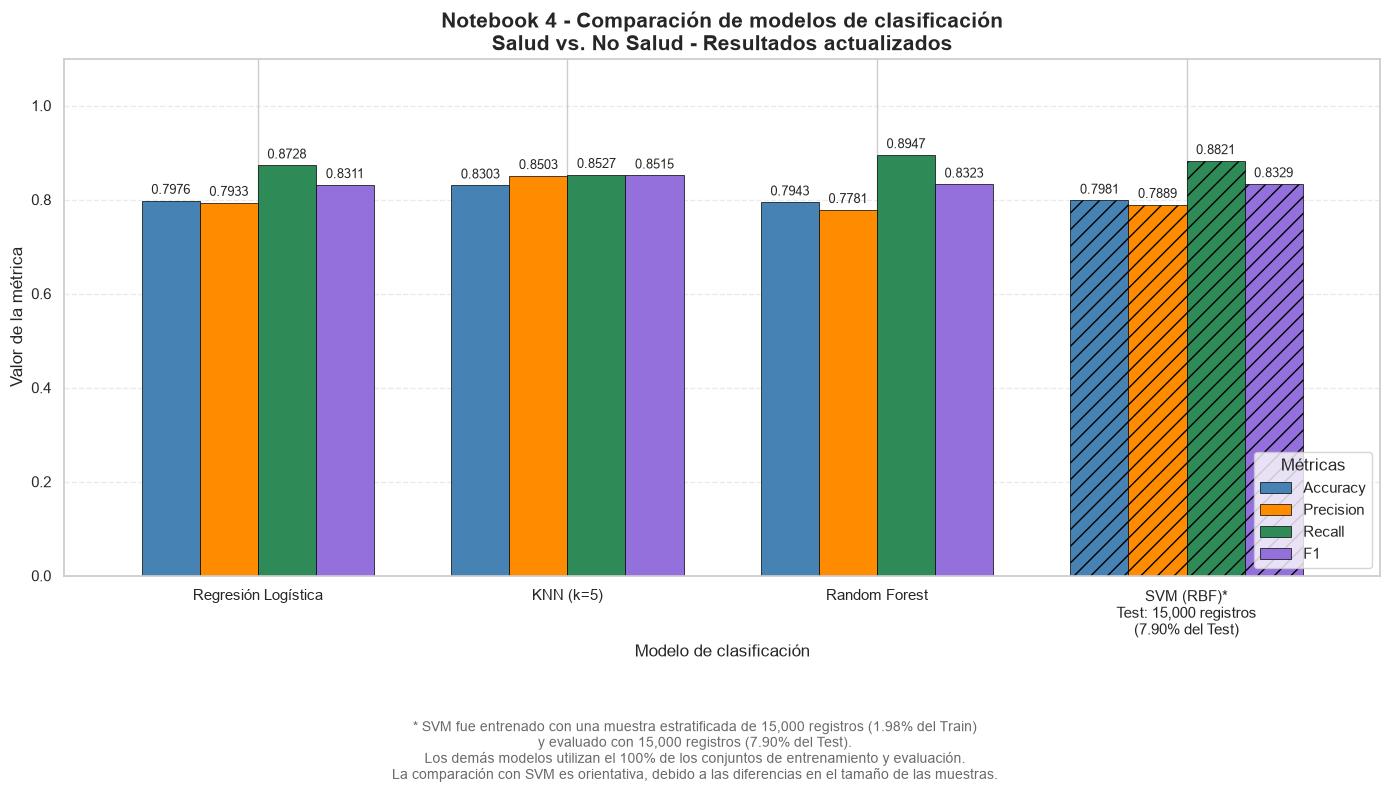

In [37]:

# ==================================================
# GRÁFICO COMPARATIVO DE MODELOS DE CLASIFICACIÓN
# NOTEBOOK 4 - RESULTADOS ACTUALIZADOS
# ==================================================

# 1. Recuperar los resultados reales de los tres modelos
# evaluados sobre el conjunto completo de Test

df_comparacion_actual = df_resultados_clasificacion.copy()

# 2. Calcular las métricas de SVM
# utilizando sus predicciones ya calculadas
# sobre la muestra estratificada de 15.000 registros

resultados_svm = {
    "Modelo": "SVM (RBF)",
    "Registros evaluados": len(y_test_svm),
    "Accuracy": accuracy_score(y_test_svm, y_pred_svm),
    "Precision": precision_score(y_test_svm, y_pred_svm),
    "Recall": recall_score(y_test_svm, y_pred_svm),
    "F1": f1_score(y_test_svm, y_pred_svm)
}

# 3. Incorporar SVM a la tabla comparativa

df_comparacion_actual = pd.concat(
    [
        df_comparacion_actual,
        pd.DataFrame([resultados_svm])
    ],
    ignore_index=True
)

# 4. Incorporar cantidad de registros de entrenamiento

df_comparacion_actual["Registros entrenamiento"] = (
    df_comparacion_actual["Modelo"].map({
        "Regresión Logística": len(y_train),
        "KNN (k=5)": len(y_train),
        "Random Forest": len(y_train),
        "SVM (RBF)": len(y_train_svm)
    })
)

# 5. Calcular porcentajes utilizados

df_comparacion_actual["% Train utilizado"] = (
    df_comparacion_actual["Registros entrenamiento"]
    / len(y_train) * 100
)

df_comparacion_actual["% Test utilizado"] = (
    df_comparacion_actual["Registros evaluados"]
    / len(y_test) * 100
)

# 6. Mantener el mismo orden de los modelos
# para facilitar la comparación visual

orden_modelos = [
    "Regresión Logística",
    "KNN (k=5)",
    "Random Forest",
    "SVM (RBF)"
]

df_comparacion_actual = (
    df_comparacion_actual
    .set_index("Modelo")
    .loc[orden_modelos]
    .reset_index()
)

# 7. Mostrar la tabla comparativa actualizada

print("COMPARACIÓN DE MODELOS - NOTEBOOK 4")
print("Resultados reales del modelado actualizado\n")

display(df_comparacion_actual.round(4))

# 8. Preparar los datos para el gráfico

metricas = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
]

df_grafico_modelos = (
    df_comparacion_actual
    .set_index("Modelo")[metricas]
)

# 9. Generar el gráfico comparativo

ax = df_grafico_modelos.plot(
    kind="bar",
    figsize=(14, 8),
    width=0.75,
    color=[
        "steelblue",
        "darkorange",
        "seagreen",
        "mediumpurple"
    ],
    edgecolor="black",
    linewidth=0.5
)

# 10. Configurar títulos y ejes

ax.set_title(
    "Notebook 4 - Comparación de modelos de clasificación\n"
    "Salud vs. No Salud - Resultados actualizados",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Modelo de clasificación", fontsize=12)
ax.set_ylabel("Valor de la métrica", fontsize=12)

ax.set_ylim(0, 1.10)

# 11. Personalizar etiquetas de los modelos

porcentaje_test_svm = (
    len(y_test_svm) / len(y_test) * 100
)

ax.set_xticklabels(
    [
        "Regresión Logística",
        "KNN (k=5)",
        "Random Forest",
        f"SVM (RBF)*\n"
        f"Test: {len(y_test_svm):,} registros\n"
        f"({porcentaje_test_svm:.2f}% del Test)"
    ],
    rotation=0
)

# 12. Mostrar los valores sobre las barras

for contenedor in ax.containers:

    ax.bar_label(
        contenedor,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

# 13. Diferenciar visualmente las barras de SVM
# mediante un tramado

for contenedor in ax.containers:

    barra_svm = contenedor[-1]

    barra_svm.set_hatch("//")
    barra_svm.set_edgecolor("black")

# 14. Configurar leyenda y cuadrícula

ax.legend(
    title="Métricas",
    loc="lower right"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

# 15. Agregar aclaración metodológica al pie

porcentaje_train_svm = (
    len(y_train_svm) / len(y_train) * 100
)

nota_metodologica = (
    "* SVM fue entrenado con una muestra estratificada "
    f"de {len(y_train_svm):,} registros "
    f"({porcentaje_train_svm:.2f}% del Train)\n"
    f"y evaluado con {len(y_test_svm):,} registros "
    f"({porcentaje_test_svm:.2f}% del Test).\n"
    "Los demás modelos utilizan el 100% de los "
    "conjuntos de entrenamiento y evaluación.\n"
    "La comparación con SVM es orientativa, "
    "debido a las diferencias en el tamaño de las muestras."
)

plt.figtext(
    0.5,
    0.02,
    nota_metodologica,
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.15, 1, 1])

plt.show()



### Comparación de resultados entre la tercera y cuarta preentrega

Se conserva el gráfico correspondiente a la tercera preentrega como referencia histórica del desempeño de los modelos de clasificación.

A continuación, se presentan los resultados actualizados de la cuarta preentrega, obtenidos después de las correcciones realizadas en la definición de la variable objetivo, la selección de características predictoras y el preprocesamiento de los datos.

Esta comparación permite visualizar la evolución del desempeño de los modelos de:

- **Regresión Logística**
- **K-Nearest Neighbors (KNN)**
- **Random Forest**
- **Support Vector Machine (SVM)**

#### Consideración metodológica sobre SVM

Debido al elevado costo computacional del algoritmo con kernel RBF, se utilizaron muestras estratificadas de **15.000 registros para entrenamiento** y **15.000 registros para evaluación**.

Estas muestras representan aproximadamente:

- **1,98%** del conjunto de entrenamiento (Train).
- **7,90%** del conjunto de evaluación (Test).

Por este motivo, los resultados de SVM se incluyen con fines comparativos y exploratorios, pero deben interpretarse considerando que fueron obtenidos bajo condiciones de entrenamiento y evaluación diferentes a las de los otros tres modelos.

#### Interpretación de los resultados

Asimismo, las diferencias entre los resultados de ambas preentregas no pueden atribuirse exclusivamente a una mejora de los algoritmos, dado que también se modificaron aspectos metodológicos del modelado, entre ellos:

- La definición de la variable objetivo.
- La selección de las variables predictoras.
- El preprocesamiento de las variables categóricas y numéricas.
- La prevención de posibles fugas de información (*Data Leakage*).

**Nota:** la comparación entre ambas preentregas permite observar la evolución del proyecto y el impacto conjunto de las correcciones implementadas, mientras que la comparación con SVM debe interpretarse considerando las diferencias en los tamaños de las muestras utilizadas.


<span style="font-size: 18px; font-weight: bold; color: #003366;">Comparativa General de Rendimiento</span>


**Análisis Detallado por Modelo**

- **Random Forest** (El Modelo Óptimo y Campeón Absoluto):

    - Accuracy: 86.43%

    - Precision: 90.39% (¡Sobresaliente!)

    - Recall: 85.29%

    - F1-Score: 87.77%

    **Conclusión:** Random Forest se posiciona indiscutiblemente como el modelo a implementar. Una precisión del 90.39% significa que de cada 10 alertas que emita el sistema sobre ausencias particulares, más de 9 son totalmente acertadas (reduciendo al mínimo las falsas alarmas), manteniendo al mismo tiempo una sensibilidad superior al 85%.

- **KNN** (k=5) (Excelente Alternativa de Alta Estabilidad):

    - Accuracy: 83.78% | Precision: 86.28% | Recall: 85.10% | F1-Score: 85.69%

    **Conclusión:** Demuestra que la cercanía de perfiles combinada con la estacionalidad genera un clúster sumamente predecible. Su simetría entre precisión y sensibilidad (ambas en torno al 85-86%) lo valida como un modelo secundario de respaldo muy confiable.

- **Regresión Logística** (El Baseline Solucionado):

    - Accuracy: 76.98% | Precision: 78.31% | Recall: 82.50% | F1-Score: 80.35%

    **Conclusión:** Al fin muestra un comportamiento digno, superando el 80% de F1-Score gracias al aporte de la nueva variable. Sin embargo, continúa quedando rezagado frente a los modelos no lineales (~7 puntos porcentuales por debajo de Random Forest), lo que ratifica que la naturaleza del ausentismo se beneficia de estructuras de decisión complejas.



<span style="font-size: 20px; font-weight: bold; color: #003366;">Curvas ROC y AUC</span>

In [39]:
# ==================================================
# DIAGNÓSTICO PREVIO A CURVAS ROC-AUC
# ==================================================

from pathlib import Path

print("VERIFICACIÓN DE VARIABLES\n")

variables_roc = [
    "y_test",
    "y_test_svm",
    "modelo_logistica",
    "modelo_rf",
    "modelo_svm",
    "X_test_esc",
    "X_test_svm",
    "y_pred_knn",
    "y_prob_knn"
]

for variable in variables_roc:

    if variable in globals():
        print(f"{variable}: DISPONIBLE")
    else:
        print(f"{variable}: NO DISPONIBLE")

print("\nVERIFICACIÓN DE PROBABILIDADES KNN")

if "y_prob_knn" in globals():

    print("Cantidad de probabilidades:", len(y_prob_knn))
    print("Cantidad de registros Test:", len(y_test))

    assert len(y_prob_knn) == len(y_test)

    print("Probabilidades KNN: VALIDACIÓN CORRECTA")

print("\nVERIFICACIÓN DEL ARCHIVO TEMPORAL")

archivo_knn = Path("resultados_knn_temporal.npz")

print("Archivo guardado:", archivo_knn.exists())
print("Ubicación:", archivo_knn.resolve())

VERIFICACIÓN DE VARIABLES

y_test: DISPONIBLE
y_test_svm: DISPONIBLE
modelo_logistica: DISPONIBLE
modelo_rf: DISPONIBLE
modelo_svm: DISPONIBLE
X_test_esc: DISPONIBLE
X_test_svm: DISPONIBLE
y_pred_knn: DISPONIBLE
y_prob_knn: DISPONIBLE

VERIFICACIÓN DE PROBABILIDADES KNN
Cantidad de probabilidades: 189806
Cantidad de registros Test: 189806
Probabilidades KNN: VALIDACIÓN CORRECTA

VERIFICACIÓN DEL ARCHIVO TEMPORAL
Archivo guardado: True
Ubicación: C:\Users\gn_d4\Documents\GERMÁN\DATA SCIENCE\GitHub\python\PruebaAusentismo\resultados_knn_temporal.npz


In [42]:

# ==================================================
# KNN - VERIFICAR RESULTADOS DISPONIBLES
# ==================================================

from pathlib import Path

archivo_knn = Path("resultados_knn_temporal.npz")

print("ESTADO DE LOS RESULTADOS KNN\n")

print(
    "Modelo KNN disponible:",
    "modelo_knn" in globals()
)

print(
    "Predicciones KNN disponibles:",
    "y_pred_knn" in globals()
)

print(
    "Probabilidades KNN disponibles:",
    "y_prob_knn" in globals()
)

print(
    "Archivo temporal disponible:",
    archivo_knn.exists()
)

# Verificar el contenido del archivo, si existe

if archivo_knn.exists():

    with np.load(archivo_knn) as resultados:

        print("\nContenido del archivo temporal:")
        print(resultados.files)


ESTADO DE LOS RESULTADOS KNN

Modelo KNN disponible: True
Predicciones KNN disponibles: True
Probabilidades KNN disponibles: True
Archivo temporal disponible: True

Contenido del archivo temporal:
['y_pred_knn', 'y_prob_knn', 'y_test', 'indices_test', 'accuracy', 'precision', 'recall', 'f1', 'auc']


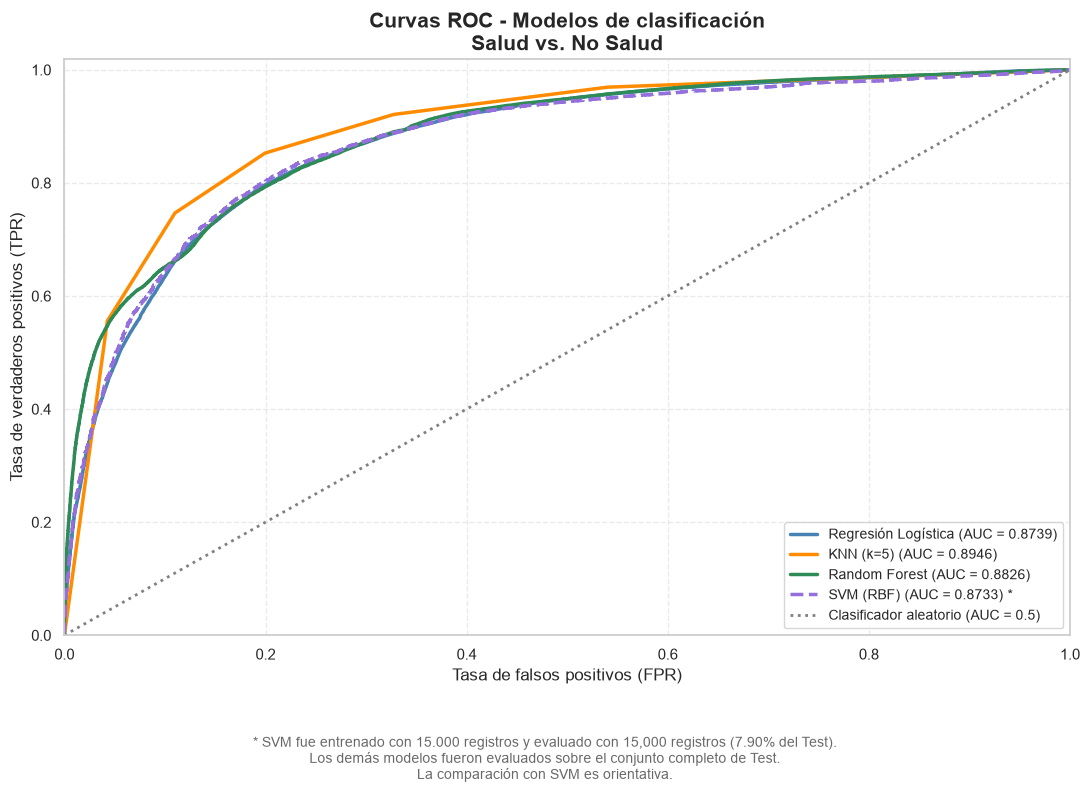

RESULTADOS ROC-AUC - NOTEBOOK 4



,Modelo,ROC-AUC,Registros evaluados,% Test utilizado
0,KNN (k=5),0.8946,189806,100.0000
1,Random Forest,0.8826,189806,100.0000
2,Regresión Logística,0.8739,189806,100.0000
3,SVM (RBF),0.8733,15000,7.9028


In [43]:

# ==================================================
# CURVAS ROC Y AUC - MODELOS DE CLASIFICACIÓN
# NOTEBOOK 4 - RESULTADOS ACTUALIZADOS
# ==================================================

from sklearn.metrics import roc_curve, roc_auc_score

# --------------------------------------------------
# 1. Obtener los scores de cada modelo
# --------------------------------------------------

# Regresión Logística

y_prob_logistica = modelo_logistica.predict_proba(
    X_test_esc
)[:, 1]

# KNN
# Reutilizamos las probabilidades guardadas previamente
# NO volver a ejecutar predict_proba()

# y_prob_knn ya debe estar disponible

# Random Forest

y_prob_rf = modelo_rf.predict_proba(
    X_test_esc
)[:, 1]

# SVM
# Utilizamos decision_function sobre su muestra de Test

y_score_svm = modelo_svm.decision_function(
    X_test_svm
)

# --------------------------------------------------
# 2. Organizar los resultados de cada modelo
# --------------------------------------------------

resultados_roc = {
    "Regresión Logística": {
        "y_real": y_test,
        "y_score": y_prob_logistica,
        "color": "steelblue"
    },

    "KNN (k=5)": {
        "y_real": y_test,
        "y_score": y_prob_knn,
        "color": "darkorange"
    },

    "Random Forest": {
        "y_real": y_test,
        "y_score": y_prob_rf,
        "color": "seagreen"
    },

    "SVM (RBF)": {
        "y_real": y_test_svm,
        "y_score": y_score_svm,
        "color": "mediumpurple"
    }
}

# --------------------------------------------------
# 3. Crear gráfico y tabla de resultados
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 8))

resultados_auc = []

for nombre, datos in resultados_roc.items():

    y_real = datos["y_real"]
    y_score = datos["y_score"]

    # Validar dimensiones

    assert len(y_real) == len(y_score), (
        f"Error en las dimensiones de {nombre}"
    )

    # Calcular curva ROC

    fpr, tpr, thresholds = roc_curve(
        y_real,
        y_score,
        pos_label=1
    )

    # Calcular AUC

    auc_modelo = roc_auc_score(
        y_real,
        y_score
    )

    # Guardar resultados

    resultados_auc.append({
        "Modelo": nombre,
        "ROC-AUC": auc_modelo,
        "Registros evaluados": len(y_real),
        "% Test utilizado": (
            len(y_real) / len(y_test) * 100
        )
    })

    # Diferenciar SVM visualmente

    estilo_linea = "--" if nombre == "SVM (RBF)" else "-"

    etiqueta = f"{nombre} (AUC = {auc_modelo:.4f})"

    if nombre == "SVM (RBF)":
        etiqueta += " *"

    # Graficar curva ROC

    ax.plot(
        fpr,
        tpr,
        label=etiqueta,
        color=datos["color"],
        linewidth=2.5,
        linestyle=estilo_linea
    )

# --------------------------------------------------
# 4. Línea de referencia aleatoria
# --------------------------------------------------

ax.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle=":",
    linewidth=2,
    label="Clasificador aleatorio (AUC = 0.5)"
)

# --------------------------------------------------
# 5. Configurar gráfico
# --------------------------------------------------

ax.set_title(
    "Curvas ROC - Modelos de clasificación\n"
    "Salud vs. No Salud",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Tasa de falsos positivos (FPR)",
    fontsize=12
)

ax.set_ylabel(
    "Tasa de verdaderos positivos (TPR)",
    fontsize=12
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower right", fontsize=10)

ax.grid(
    linestyle="--",
    alpha=0.4
)

# --------------------------------------------------
# 6. Aclaración metodológica de SVM
# --------------------------------------------------

porcentaje_test_svm = (
    len(y_test_svm) / len(y_test) * 100
)

nota_roc = (
    "* SVM fue entrenado con 15.000 registros y "
    f"evaluado con {len(y_test_svm):,} registros "
    f"({porcentaje_test_svm:.2f}% del Test).\n"
    "Los demás modelos fueron evaluados sobre "
    "el conjunto completo de Test.\n"
    "La comparación con SVM es orientativa."
)

fig.text(
    0.5,
    0.02,
    nota_roc,
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.12, 1, 1])

plt.show()

# --------------------------------------------------
# 7. Tabla comparativa ROC-AUC
# --------------------------------------------------

df_resultados_auc = pd.DataFrame(
    resultados_auc
).sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("RESULTADOS ROC-AUC - NOTEBOOK 4\n")

display(df_resultados_auc.round(4))


### Análisis e interpretación de las curvas ROC-AUC

Las curvas ROC permiten evaluar la capacidad de discriminación de los modelos de clasificación entre las licencias por Salud (clase 1) y No Salud (clase 0), considerando diferentes umbrales de decisión.

Los resultados obtenidos fueron:

- **KNN (k=5):** ROC-AUC = 0.8946.
- **Random Forest:** ROC-AUC = 0.8826.
- **Regresión Logística:** ROC-AUC = 0.8739.
- **SVM (RBF):** ROC-AUC = 0.8733.

Todos los modelos presentan una capacidad de discriminación considerablemente superior a la de un clasificador aleatorio, cuyo ROC-AUC es igual a 0.50.

KNN obtiene el mayor valor de ROC-AUC, lo que indica que presenta la mejor capacidad global de discriminación entre ambas clases dentro de los modelos evaluados sobre el conjunto completo de Test. Este resultado es consistente con las métricas de Accuracy, Precision y F1-Score obtenidas previamente, en las cuales también presenta el mejor desempeño.

Random Forest alcanza el segundo mayor ROC-AUC y el mayor Recall, destacándose por su capacidad para identificar correctamente las licencias por Salud. Por este motivo, constituye un candidato relevante para la siguiente etapa de optimización de hiperparámetros.

Regresión Logística presenta un rendimiento competitivo y constituye un modelo de referencia para evaluar el aporte de algoritmos más complejos.

En el caso de SVM, los resultados deben interpretarse con cautela, debido a que fue entrenado con una muestra estratificada de 15.000 registros y evaluado sobre otros 15.000 registros, equivalentes al 7.90% del conjunto completo de Test. Por lo tanto, su comparación con los demás modelos es orientativa.

### Conclusión preliminar

Los resultados obtenidos posicionan a KNN como el modelo con mejor desempeño general en la configuración actual. Sin embargo, antes de seleccionar el modelo definitivo, se realizará una optimización de los hiperparámetros de Random Forest, utilizando exclusivamente datos de entrenamiento y validación para la selección de su configuración.

La elección final considerará las métricas de clasificación, la capacidad de discriminación, el costo computacional y las limitaciones metodológicas de la evaluación.



## Optimización de hiperparámetros de Random Forest

A partir de los resultados obtenidos en la evaluación de los modelos de clasificación, se propone optimizar los hiperparámetros de Random Forest con el objetivo de mejorar su capacidad predictiva.

El modelo base, configurado con 100 árboles y una profundidad máxima de 12, obtuvo un F1-Score de 0.8323 y un ROC-AUC de 0.8826 sobre el conjunto completo de Test.

La optimización se realizará mediante una búsqueda acotada de configuraciones, utilizando una partición interna del conjunto de entrenamiento para evaluar los hiperparámetros.

Se analizarán los siguientes parámetros:

- n_estimators: cantidad de árboles.
- max_depth: profundidad máxima de los árboles.
- min_samples_split: cantidad mínima de registros para dividir un nodo.
- min_samples_leaf: cantidad mínima de registros en una hoja.
- max_features: cantidad de variables consideradas en cada división.
- class_weight: ponderación de las clases.

La selección de la mejor configuración se realizará considerando las métricas de validación, principalmente F1-Score y ROC-AUC, junto con el costo computacional.

Finalmente, se comparará el modelo optimizado con el Random Forest base y los demás modelos de clasificación evaluados anteriormente.


In [44]:

# ==================================================
# RANDOM FOREST - OPTIMIZACIÓN DE HIPERPARÁMETROS
# PASO 1: VERIFICACIÓN DE DATOS DISPONIBLES
# ==================================================

print("VERIFICACIÓN DE VARIABLES\n")

variables_optimizacion = [
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "X_train_exp",
    "X_val_exp",
    "y_train_exp",
    "y_val_exp",
    "X_train_con_rem",
    "X_val_con_rem",
    "preprocesador_con_remuneracion",
    "modelo_rf"
]

for variable in variables_optimizacion:

    if variable in globals():
        print(f"{variable}: DISPONIBLE")
    else:
        print(f"{variable}: NO DISPONIBLE")

print("\nDIMENSIONES DE LOS CONJUNTOS")

print("Train completo:", X_train.shape)
print("Test completo:", X_test.shape)

if "X_train_exp" in globals():

    print("\nEntrenamiento interno:", X_train_exp.shape)
    print("Validación interna:", X_val_exp.shape)

if "X_train_con_rem" in globals():

    print("\nEntrenamiento preprocesado:",
          X_train_con_rem.shape)

    print("Validación preprocesada:",
          X_val_con_rem.shape)

print("\nHIPERPARÁMETROS DEL RANDOM FOREST BASE")

parametros_rf = modelo_rf.get_params()

for parametro in [
    "n_estimators",
    "max_depth",
    "min_samples_split",
    "min_samples_leaf",
    "max_features",
    "class_weight",
    "random_state",
    "n_jobs"
]:

    print(f"{parametro}: {parametros_rf[parametro]}")


VERIFICACIÓN DE VARIABLES

X_train: DISPONIBLE
y_train: DISPONIBLE
X_test: DISPONIBLE
y_test: DISPONIBLE
X_train_exp: DISPONIBLE
X_val_exp: DISPONIBLE
y_train_exp: DISPONIBLE
y_val_exp: DISPONIBLE
X_train_con_rem: DISPONIBLE
X_val_con_rem: DISPONIBLE
preprocesador_con_remuneracion: DISPONIBLE
modelo_rf: DISPONIBLE

DIMENSIONES DE LOS CONJUNTOS
Train completo: (759221, 11)
Test completo: (189806, 11)

Entrenamiento interno: (607376, 11)
Validación interna: (151845, 11)

Entrenamiento preprocesado: (607376, 695)
Validación preprocesada: (151845, 695)

HIPERPARÁMETROS DEL RANDOM FOREST BASE
n_estimators: 100
max_depth: 12
min_samples_split: 2
min_samples_leaf: 1
max_features: sqrt
class_weight: None
random_state: 42
n_jobs: -1


In [45]:

# ==================================================
# RANDOM FOREST - OPTIMIZACIÓN DE HIPERPARÁMETROS
# PASO 2: MODELO BASE SOBRE VALIDACIÓN INTERNA
# ==================================================

import time

from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Crear una copia de la configuración original
# clone() conserva los hiperparámetros,
# pero no copia el entrenamiento del modelo.

modelo_rf_base_val = clone(modelo_rf)

print("CONFIGURACIÓN DEL RANDOM FOREST BASE\n")

print("Cantidad de árboles:",
      modelo_rf_base_val.n_estimators)

print("Profundidad máxima:",
      modelo_rf_base_val.max_depth)

print("\nIniciando entrenamiento del modelo base...")

inicio = time.time()

# 2. Entrenar exclusivamente sobre el Train interno

modelo_rf_base_val.fit(
    X_train_con_rem,
    y_train_exp
)

fin_entrenamiento = time.time()

print("Entrenamiento finalizado.")

# 3. Obtener predicciones y probabilidades
# sobre el conjunto de validación interna

y_pred_rf_base_val = modelo_rf_base_val.predict(
    X_val_con_rem
)

y_prob_rf_base_val = modelo_rf_base_val.predict_proba(
    X_val_con_rem
)[:, 1]

# 4. Calcular métricas de validación

resultados_rf_base_val = {
    "Modelo": "Random Forest Base",
    "Registros entrenamiento": len(y_train_exp),
    "Registros validación": len(y_val_exp),

    "Accuracy": accuracy_score(
        y_val_exp,
        y_pred_rf_base_val
    ),

    "Precision": precision_score(
        y_val_exp,
        y_pred_rf_base_val
    ),

    "Recall": recall_score(
        y_val_exp,
        y_pred_rf_base_val
    ),

    "F1": f1_score(
        y_val_exp,
        y_pred_rf_base_val
    ),

    "ROC-AUC": roc_auc_score(
        y_val_exp,
        y_prob_rf_base_val
    ),

    "Tiempo entrenamiento (segundos)": (
        fin_entrenamiento - inicio
    )
}

# 5. Construir tabla de resultados

df_rf_base_val = pd.DataFrame(
    [resultados_rf_base_val]
)

print("\nRESULTADOS RANDOM FOREST BASE")
print("VALIDACIÓN INTERNA\n")

display(df_rf_base_val.round(4))

# 6. Mostrar tiempo de ejecución

fin = time.time()

tiempo_entrenamiento = fin_entrenamiento - inicio
tiempo_total = fin - inicio

minutos = int(tiempo_entrenamiento // 60)
segundos = tiempo_entrenamiento % 60

print(
    f"\nTiempo de entrenamiento: "
    f"{minutos} minutos y {segundos:.2f} segundos"
)

minutos_total = int(tiempo_total // 60)
segundos_total = tiempo_total % 60

print(
    f"Tiempo total de ejecución: "
    f"{minutos_total} minutos y "
    f"{segundos_total:.2f} segundos"
)


CONFIGURACIÓN DEL RANDOM FOREST BASE

Cantidad de árboles: 100
Profundidad máxima: 12

Iniciando entrenamiento del modelo base...
Entrenamiento finalizado.

RESULTADOS RANDOM FOREST BASE
VALIDACIÓN INTERNA



,Modelo,Registros entrenamiento,Registros validación,Accuracy,Precision,Recall,F1,ROC-AUC,Tiempo entrenamiento (segundos)
0,Random Forest Base,607376,151845,0.7948,0.7785,0.8951,0.8327,0.8848,20.1907



Tiempo de entrenamiento: 0 minutos y 20.19 segundos
Tiempo total de ejecución: 0 minutos y 20.57 segundos


In [46]:

# ==================================================
# RANDOM FOREST - OPTIMIZACIÓN DE HIPERPARÁMETROS
# PASO 3: BÚSQUEDA ACOTADA DE CONFIGURACIONES
# ==================================================

import time

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Definir las configuraciones a evaluar

configuraciones_rf = [

    {
        "Configuracion": "RF_01",
        "n_estimators": 200,
        "max_depth": 12,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": "sqrt",
        "class_weight": None
    },

    {
        "Configuracion": "RF_02",
        "n_estimators": 100,
        "max_depth": 18,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": "sqrt",
        "class_weight": None
    },

    {
        "Configuracion": "RF_03",
        "n_estimators": 100,
        "max_depth": 25,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": "sqrt",
        "class_weight": None
    },

    {
        "Configuracion": "RF_04",
        "n_estimators": 100,
        "max_depth": 18,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": None
    },

    {
        "Configuracion": "RF_05",
        "n_estimators": 100,
        "max_depth": 25,
        "min_samples_split": 10,
        "min_samples_leaf": 4,
        "max_features": "sqrt",
        "class_weight": None
    },

    {
        "Configuracion": "RF_06",
        "n_estimators": 200,
        "max_depth": 18,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": None
    },

    {
        "Configuracion": "RF_07",
        "n_estimators": 100,
        "max_depth": 18,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": 0.1,
        "class_weight": None
    },

    {
        "Configuracion": "RF_08",
        "n_estimators": 100,
        "max_depth": 18,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": "balanced"
    },

    {
        "Configuracion": "RF_09",
        "n_estimators": 200,
        "max_depth": 25,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": None
    },

    {
        "Configuracion": "RF_10",
        "n_estimators": 100,
        "max_depth": 18,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": "log2",
        "class_weight": None
    }

]

# 2. Inicializar la búsqueda

resultados_busqueda_rf = []

inicio_busqueda = time.time()

print("INICIO DE OPTIMIZACIÓN RANDOM FOREST")
print("Configuraciones a evaluar:",
      len(configuraciones_rf))

# 3. Entrenar y evaluar cada configuración

for i, configuracion in enumerate(
    configuraciones_rf, start=1
):

    nombre = configuracion["Configuracion"]

    parametros = {
        clave: valor
        for clave, valor in configuracion.items()
        if clave != "Configuracion"
    }

    print("\n" + "=" * 50)

    print(
        f"Configuración {i}/"
        f"{len(configuraciones_rf)}: {nombre}",
        flush=True
    )

    print(parametros)

    # Crear un modelo independiente
    # Conservamos random_state y n_jobs del modelo base

    modelo_rf_candidato = clone(modelo_rf)

    modelo_rf_candidato.set_params(
        **parametros
    )

    # Entrenamiento interno

    inicio_modelo = time.time()

    modelo_rf_candidato.fit(
        X_train_con_rem,
        y_train_exp
    )

    tiempo_entrenamiento = (
        time.time() - inicio_modelo
    )

    # Evaluación sobre validación interna

    y_pred_rf_candidato = (
        modelo_rf_candidato.predict(
            X_val_con_rem
        )
    )

    y_prob_rf_candidato = (
        modelo_rf_candidato.predict_proba(
            X_val_con_rem
        )[:, 1]
    )

    # Calcular métricas

    resultado = {

        "Configuracion": nombre,

        **parametros,

        "Accuracy": accuracy_score(
            y_val_exp,
            y_pred_rf_candidato
        ),

        "Precision": precision_score(
            y_val_exp,
            y_pred_rf_candidato
        ),

        "Recall": recall_score(
            y_val_exp,
            y_pred_rf_candidato
        ),

        "F1": f1_score(
            y_val_exp,
            y_pred_rf_candidato
        ),

        "ROC-AUC": roc_auc_score(
            y_val_exp,
            y_prob_rf_candidato
        ),

        "Tiempo entrenamiento (segundos)": (
            tiempo_entrenamiento
        )
    }

    resultados_busqueda_rf.append(resultado)

    # Mostrar progreso

    minutos = int(tiempo_entrenamiento // 60)
    segundos = tiempo_entrenamiento % 60

    print(f"F1: {resultado['F1']:.4f}")
    print(f"ROC-AUC: {resultado['ROC-AUC']:.4f}")

    print(
        f"Tiempo: {minutos} minutos "
        f"y {segundos:.2f} segundos"
    )

    # Liberar el modelo candidato para evitar
    # acumular todos los bosques en memoria

    del modelo_rf_candidato

# 4. Incorporar el Random Forest base

resultado_base = {

    "Configuracion": "RF_BASE",

    "n_estimators": modelo_rf.n_estimators,

    "max_depth": modelo_rf.max_depth,

    "min_samples_split": (
        modelo_rf.min_samples_split
    ),

    "min_samples_leaf": (
        modelo_rf.min_samples_leaf
    ),

    "max_features": modelo_rf.max_features,

    "class_weight": modelo_rf.class_weight,

    "Accuracy": resultados_rf_base_val["Accuracy"],

    "Precision": resultados_rf_base_val["Precision"],

    "Recall": resultados_rf_base_val["Recall"],

    "F1": resultados_rf_base_val["F1"],

    "ROC-AUC": resultados_rf_base_val["ROC-AUC"],

    "Tiempo entrenamiento (segundos)": (
        resultados_rf_base_val[
            "Tiempo entrenamiento (segundos)"
        ]
    )
}

resultados_busqueda_rf.append(resultado_base)

# 5. Construir tabla comparativa
# Ordenamos por F1 y utilizamos ROC-AUC
# como segundo criterio de ordenamiento

df_busqueda_rf = (
    pd.DataFrame(resultados_busqueda_rf)
    .sort_values(
        ["F1", "ROC-AUC"],
        ascending=False
    )
    .reset_index(drop=True)
)

# 6. Mostrar resultados finales

print("\n" + "=" * 50)

print("RESULTADOS DE OPTIMIZACIÓN")
print("RANDOM FOREST - VALIDACIÓN INTERNA\n")

display(df_busqueda_rf.round(4))

# 7. Mostrar la configuración mejor posicionada

print("\nMEJOR CONFIGURACIÓN SEGÚN F1\n")

display(df_busqueda_rf.head(1).round(4))

# 8. Tiempo total de búsqueda

tiempo_busqueda = time.time() - inicio_busqueda

minutos_total = int(tiempo_busqueda // 60)
segundos_total = tiempo_busqueda % 60

print(
    f"\nTiempo total de búsqueda: "
    f"{minutos_total} minutos y "
    f"{segundos_total:.2f} segundos"
)


INICIO DE OPTIMIZACIÓN RANDOM FOREST
Configuraciones a evaluar: 10

Configuración 1/10: RF_01
{'n_estimators': 200, 'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': None}
F1: 0.8328
ROC-AUC: 0.8844
Tiempo: 0 minutos y 41.66 segundos

Configuración 2/10: RF_02
{'n_estimators': 100, 'max_depth': 18, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': None}
F1: 0.8334
ROC-AUC: 0.8979
Tiempo: 0 minutos y 57.48 segundos

Configuración 3/10: RF_03
{'n_estimators': 100, 'max_depth': 25, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': None}
F1: 0.8380
ROC-AUC: 0.9090
Tiempo: 2 minutos y 24.55 segundos

Configuración 4/10: RF_04
{'n_estimators': 100, 'max_depth': 18, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'class_weight': None}
F1: 0.8331
ROC-AUC: 0.8957
Tiempo: 0 minutos y 44.52 segundos

Configuración 5/10: RF_05
{'n_estimators': 100, 

,Configuracion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight,Accuracy,Precision,Recall,F1,ROC-AUC,Tiempo entrenamiento (segundos)
0,RF_07,100,18,5,2,0.1,NaN,0.8053,0.7886,0.9001,0.8407,0.9043,74.3839
1,RF_03,100,25,2,1,sqrt,NaN,0.8013,0.7838,0.9003,0.8380,0.9090,144.5459
2,RF_09,200,25,5,2,sqrt,NaN,0.7992,0.7822,0.8981,0.8362,0.9062,158.1899
3,RF_05,100,25,10,4,sqrt,NaN,0.7973,0.7808,0.8965,0.8347,0.9029,66.8714
4,RF_08,100,18,5,2,sqrt,balanced,0.7970,0.7811,0.8951,0.8342,0.8961,50.6315
5,RF_02,100,18,2,1,sqrt,NaN,0.7956,0.7791,0.8959,0.8334,0.8979,57.4806
6,RF_04,100,18,5,2,sqrt,NaN,0.7952,0.7788,0.8955,0.8331,0.8957,44.5154
7,RF_10,100,18,5,2,log2,NaN,0.7949,0.7778,0.8966,0.8330,0.8858,24.3166
8,RF_06,200,18,5,2,sqrt,NaN,0.7950,0.7786,0.8955,0.8330,0.8956,84.0192
9,RF_01,200,12,2,1,sqrt,NaN,0.7948,0.7785,0.8952,0.8328,0.8844,41.6599



MEJOR CONFIGURACIÓN SEGÚN F1



,Configuracion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight,Accuracy,Precision,Recall,F1,ROC-AUC,Tiempo entrenamiento (segundos)
0,RF_07,100,18,5,2,0.1,NaN,0.8053,0.7886,0.9001,0.8407,0.9043,74.3839



Tiempo total de búsqueda: 12 minutos y 33.55 segundos


In [47]:

# ==================================================
# RANDOM FOREST - OPTIMIZACIÓN DE HIPERPARÁMETROS
# PASO 4: ANÁLISIS DE RESULTADOS
# ==================================================

print("RESULTADOS COMPLETOS DE LA OPTIMIZACIÓN\n")

columnas_resultados_rf = [
    "Configuracion",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Tiempo entrenamiento (segundos)"
]

display(
    df_busqueda_rf[columnas_resultados_rf]
    .round(4)
)

# 1. Identificar la mejor configuración según F1

mejor_rf_f1 = df_busqueda_rf.iloc[0]

print("\nMEJOR CONFIGURACIÓN SEGÚN F1")

print("Configuración:", mejor_rf_f1["Configuracion"])
print(f"F1: {mejor_rf_f1['F1']:.4f}")
print(f"ROC-AUC: {mejor_rf_f1['ROC-AUC']:.4f}")

# 2. Identificar la mejor configuración según ROC-AUC

mejor_rf_auc = df_busqueda_rf.loc[
    df_busqueda_rf["ROC-AUC"].idxmax()
]

print("\nMEJOR CONFIGURACIÓN SEGÚN ROC-AUC")

print("Configuración:", mejor_rf_auc["Configuracion"])
print(f"F1: {mejor_rf_auc['F1']:.4f}")
print(f"ROC-AUC: {mejor_rf_auc['ROC-AUC']:.4f}")

# 3. Comparar el modelo base con el mejor según F1

rf_base_resultado = df_busqueda_rf.loc[
    df_busqueda_rf["Configuracion"] == "RF_BASE"
].iloc[0]

metricas_rf = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

comparacion_rf_val = pd.DataFrame({
    "Metrica": metricas_rf,

    "Random Forest Base": [
        rf_base_resultado[metrica]
        for metrica in metricas_rf
    ],

    "Random Forest Optimizado": [
        mejor_rf_f1[metrica]
        for metrica in metricas_rf
    ]
})

comparacion_rf_val["Diferencia"] = (
    comparacion_rf_val["Random Forest Optimizado"]
    - comparacion_rf_val["Random Forest Base"]
)

print("\nCOMPARACIÓN BASE VS. OPTIMIZADO")
print("RESULTADOS SOBRE VALIDACIÓN INTERNA\n")

display(comparacion_rf_val.round(4))

# 4. Tiempo total de búsqueda

minutos = int(tiempo_busqueda // 60)
segundos = tiempo_busqueda % 60

print(
    f"\nTiempo total de búsqueda: "
    f"{minutos} minutos y {segundos:.2f} segundos"
)


RESULTADOS COMPLETOS DE LA OPTIMIZACIÓN



,Configuracion,Accuracy,Precision,Recall,F1,ROC-AUC,Tiempo entrenamiento (segundos)
0,RF_07,0.8053,0.7886,0.9001,0.8407,0.9043,74.3839
1,RF_03,0.8013,0.7838,0.9003,0.8380,0.9090,144.5459
2,RF_09,0.7992,0.7822,0.8981,0.8362,0.9062,158.1899
3,RF_05,0.7973,0.7808,0.8965,0.8347,0.9029,66.8714
4,RF_08,0.7970,0.7811,0.8951,0.8342,0.8961,50.6315
5,RF_02,0.7956,0.7791,0.8959,0.8334,0.8979,57.4806
6,RF_04,0.7952,0.7788,0.8955,0.8331,0.8957,44.5154
7,RF_10,0.7949,0.7778,0.8966,0.8330,0.8858,24.3166
8,RF_06,0.7950,0.7786,0.8955,0.8330,0.8956,84.0192
9,RF_01,0.7948,0.7785,0.8952,0.8328,0.8844,41.6599



MEJOR CONFIGURACIÓN SEGÚN F1
Configuración: RF_07
F1: 0.8407
ROC-AUC: 0.9043

MEJOR CONFIGURACIÓN SEGÚN ROC-AUC
Configuración: RF_03
F1: 0.8380
ROC-AUC: 0.9090

COMPARACIÓN BASE VS. OPTIMIZADO
RESULTADOS SOBRE VALIDACIÓN INTERNA



,Metrica,Random Forest Base,Random Forest Optimizado,Diferencia
0,Accuracy,0.7948,0.8053,0.0105
1,Precision,0.7785,0.7886,0.0101
2,Recall,0.8951,0.9001,0.0050
3,F1,0.8327,0.8407,0.0080
4,ROC-AUC,0.8848,0.9043,0.0196



Tiempo total de búsqueda: 12 minutos y 33.55 segundos


In [48]:
display(comparacion_rf_val.round(4))

,Metrica,Random Forest Base,Random Forest Optimizado,Diferencia
0,Accuracy,0.7948,0.8053,0.0105
1,Precision,0.7785,0.7886,0.0101
2,Recall,0.8951,0.9001,0.0050
3,F1,0.8327,0.8407,0.0080
4,ROC-AUC,0.8848,0.9043,0.0196


In [49]:

# ==================================================
# RANDOM FOREST - OPTIMIZACIÓN DE HIPERPARÁMETROS
# PASO 5: ENTRENAMIENTO DEL MODELO OPTIMIZADO
# ==================================================

import time

from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Recuperar la configuración seleccionada
# según los resultados de validación interna

nombre_mejor_rf = mejor_rf_f1["Configuracion"]

configuracion_seleccionada = next(
    configuracion
    for configuracion in configuraciones_rf
    if configuracion["Configuracion"] == nombre_mejor_rf
)

parametros_rf_optimizado = {
    clave: valor
    for clave, valor in configuracion_seleccionada.items()
    if clave != "Configuracion"
}

print("RANDOM FOREST OPTIMIZADO")
print("Configuración seleccionada:", nombre_mejor_rf)

print("\nHIPERPARÁMETROS SELECCIONADOS\n")

for parametro, valor in parametros_rf_optimizado.items():
    print(f"{parametro}: {valor}")

# 2. Crear un modelo independiente
# Conservamos el Random Forest original

modelo_rf_optimizado = clone(modelo_rf)

modelo_rf_optimizado.set_params(
    **parametros_rf_optimizado
)

# 3. Verificar dimensiones

print("\nDIMENSIONES DE LOS DATOS")

print("Train completo:", X_train_esc.shape)
print("Test completo:", X_test_esc.shape)

assert X_train_esc.shape[0] == len(y_train)
assert X_test_esc.shape[0] == len(y_test)

assert (
    X_train_esc.shape[1]
    == X_test_esc.shape[1]
)

# 4. Entrenar sobre el Train completo

print("\nIniciando entrenamiento del modelo optimizado...")

inicio_rf_optimizado = time.time()

modelo_rf_optimizado.fit(
    X_train_esc,
    y_train
)

fin_entrenamiento_rf_optimizado = time.time()

print("Entrenamiento finalizado.")

# 5. Obtener predicciones y probabilidades
# sobre el conjunto completo de Test

print("\nEvaluando sobre el Test completo...")

y_pred_rf_optimizado = modelo_rf_optimizado.predict(
    X_test_esc
)

y_prob_rf_optimizado = modelo_rf_optimizado.predict_proba(
    X_test_esc
)[:, 1]

# 6. Calcular métricas de evaluación

resultados_rf_optimizado = {

    "Modelo": "Random Forest Optimizado",

    "Configuracion": nombre_mejor_rf,

    "Registros entrenamiento": len(y_train),

    "Registros evaluados": len(y_test),

    "Accuracy": accuracy_score(
        y_test,
        y_pred_rf_optimizado
    ),

    "Precision": precision_score(
        y_test,
        y_pred_rf_optimizado
    ),

    "Recall": recall_score(
        y_test,
        y_pred_rf_optimizado
    ),

    "F1": f1_score(
        y_test,
        y_pred_rf_optimizado
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        y_prob_rf_optimizado
    ),

    "Tiempo entrenamiento (segundos)": (
        fin_entrenamiento_rf_optimizado
        - inicio_rf_optimizado
    )
}

# 7. Construir tabla de resultados

df_rf_optimizado = pd.DataFrame(
    [resultados_rf_optimizado]
)

print("\nRESULTADOS RANDOM FOREST OPTIMIZADO")
print("EVALUACIÓN SOBRE TEST COMPLETO\n")

display(df_rf_optimizado.round(4))

# 8. Mostrar tiempos de ejecución

tiempo_entrenamiento_rf_optimizado = (
    fin_entrenamiento_rf_optimizado
    - inicio_rf_optimizado
)

tiempo_total_rf_optimizado = (
    time.time() - inicio_rf_optimizado
)

minutos = int(
    tiempo_entrenamiento_rf_optimizado // 60
)

segundos = (
    tiempo_entrenamiento_rf_optimizado % 60
)

print(
    f"\nTiempo de entrenamiento: "
    f"{minutos} minutos y {segundos:.2f} segundos"
)

minutos_total = int(
    tiempo_total_rf_optimizado // 60
)

segundos_total = (
    tiempo_total_rf_optimizado % 60
)

print(
    f"Tiempo total de ejecución: "
    f"{minutos_total} minutos y "
    f"{segundos_total:.2f} segundos"
)


RANDOM FOREST OPTIMIZADO
Configuración seleccionada: RF_07

HIPERPARÁMETROS SELECCIONADOS

n_estimators: 100
max_depth: 18
min_samples_split: 5
min_samples_leaf: 2
max_features: 0.1
class_weight: None

DIMENSIONES DE LOS DATOS
Train completo: (759221, 696)
Test completo: (189806, 696)

Iniciando entrenamiento del modelo optimizado...
Entrenamiento finalizado.

Evaluando sobre el Test completo...

RESULTADOS RANDOM FOREST OPTIMIZADO
EVALUACIÓN SOBRE TEST COMPLETO



,Modelo,Configuracion,Registros entrenamiento,Registros evaluados,Accuracy,Precision,Recall,F1,ROC-AUC,Tiempo entrenamiento (segundos)
0,Random Forest Optimizado,RF_07,759221,189806,0.8042,0.7874,0.8999,0.8399,0.9042,107.876



Tiempo de entrenamiento: 1 minutos y 47.88 segundos
Tiempo total de ejecución: 1 minutos y 48.48 segundos


In [50]:

# ==================================================
# COMPARACIÓN FINAL DE MODELOS DE CLASIFICACIÓN
# INCLUYE RANDOM FOREST OPTIMIZADO
# ==================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Definir los modelos y sus resultados

modelos_finales = [

    {
        "Modelo": "Regresión Logística",
        "y_real": y_test,
        "y_pred": y_pred_logistica,
        "y_score": y_prob_logistica,
        "Registros entrenamiento": len(y_train)
    },

    {
        "Modelo": "KNN",
        "y_real": y_test,
        "y_pred": y_pred_knn,
        "y_score": y_prob_knn,
        "Registros entrenamiento": len(y_train)
    },

    {
        "Modelo": "Random Forest Base",
        "y_real": y_test,
        "y_pred": y_pred_rf,
        "y_score": y_prob_rf,
        "Registros entrenamiento": len(y_train)
    },

    {
        "Modelo": "Random Forest Optimizado",
        "y_real": y_test,
        "y_pred": y_pred_rf_optimizado,
        "y_score": y_prob_rf_optimizado,
        "Registros entrenamiento": len(y_train)
    },

    {
        "Modelo": "SVM",
        "y_real": y_test_svm,
        "y_pred": y_pred_svm,
        "y_score": y_score_svm,
        "Registros entrenamiento": 15000
    }

]

# 2. Calcular las métricas de cada modelo

resultados_finales = []

for modelo in modelos_finales:

    y_real = modelo["y_real"]
    y_pred = modelo["y_pred"]
    y_score = modelo["y_score"]

    # Verificar que las dimensiones coincidan

    assert len(y_real) == len(y_pred)
    assert len(y_real) == len(y_score)

    resultados_finales.append({

        "Modelo": modelo["Modelo"],

        "Accuracy": accuracy_score(
            y_real, y_pred
        ),

        "Precision": precision_score(
            y_real, y_pred
        ),

        "Recall": recall_score(
            y_real, y_pred
        ),

        "F1": f1_score(
            y_real, y_pred
        ),

        "ROC-AUC": roc_auc_score(
            y_real, y_score
        ),

        "Registros entrenamiento": (
            modelo["Registros entrenamiento"]
        ),

        "Registros evaluados": len(y_real),

        "% Test utilizado": (
            len(y_real) / len(y_test) * 100
        )

    })

# 3. Crear tabla definitiva

df_comparacion_final = pd.DataFrame(
    resultados_finales
)

# Ordenar según F1 y ROC-AUC

df_comparacion_final = (
    df_comparacion_final
    .sort_values(
        ["F1", "ROC-AUC"],
        ascending=False
    )
    .reset_index(drop=True)
)

# 4. Mostrar tabla final

print("COMPARACIÓN FINAL DE MODELOS")
print("CLASIFICACIÓN: SALUD VS. NO SALUD\n")

display(df_comparacion_final.round(4))

# 5. Comparar exclusivamente modelos
# evaluados sobre el Test completo

df_comparacion_test_completo = (
    df_comparacion_final.loc[
        df_comparacion_final[
            "Registros evaluados"
        ] == len(y_test)
    ]
    .reset_index(drop=True)
)

print("\nMODELOS EVALUADOS SOBRE TEST COMPLETO\n")

display(
    df_comparacion_test_completo.round(4)
)

# 6. Identificar el mejor modelo
# según cada métrica

print("\nMEJOR MODELO POR MÉTRICA\n")

metricas = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

for metrica in metricas:

    mejor = df_comparacion_test_completo.loc[
        df_comparacion_test_completo[
            metrica
        ].idxmax()
    ]

    print(
        f"{metrica}: "
        f"{mejor['Modelo']} "
        f"({mejor[metrica]:.4f})"
    )

print(
    "\nNota: SVM se presenta como comparación "
    "orientativa porque fue evaluado sobre "
    "una muestra del Test."
)


COMPARACIÓN FINAL DE MODELOS
CLASIFICACIÓN: SALUD VS. NO SALUD



,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,Registros entrenamiento,Registros evaluados,% Test utilizado
0,KNN,0.8303,0.8503,0.8527,0.8515,0.8946,759221,189806,100.0000
1,Random Forest Optimizado,0.8042,0.7874,0.8999,0.8399,0.9042,759221,189806,100.0000
2,SVM,0.7981,0.7889,0.8821,0.8329,0.8733,15000,15000,7.9028
3,Random Forest Base,0.7943,0.7781,0.8947,0.8323,0.8826,759221,189806,100.0000
4,Regresión Logística,0.7976,0.7933,0.8728,0.8311,0.8739,759221,189806,100.0000



MODELOS EVALUADOS SOBRE TEST COMPLETO



,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,Registros entrenamiento,Registros evaluados,% Test utilizado
0,KNN,0.8303,0.8503,0.8527,0.8515,0.8946,759221,189806,100.0
1,Random Forest Optimizado,0.8042,0.7874,0.8999,0.8399,0.9042,759221,189806,100.0
2,Random Forest Base,0.7943,0.7781,0.8947,0.8323,0.8826,759221,189806,100.0
3,Regresión Logística,0.7976,0.7933,0.8728,0.8311,0.8739,759221,189806,100.0



MEJOR MODELO POR MÉTRICA

Accuracy: KNN (0.8303)
Precision: KNN (0.8503)
Recall: Random Forest Optimizado (0.8999)
F1: KNN (0.8515)
ROC-AUC: Random Forest Optimizado (0.9042)

Nota: SVM se presenta como comparación orientativa porque fue evaluado sobre una muestra del Test.


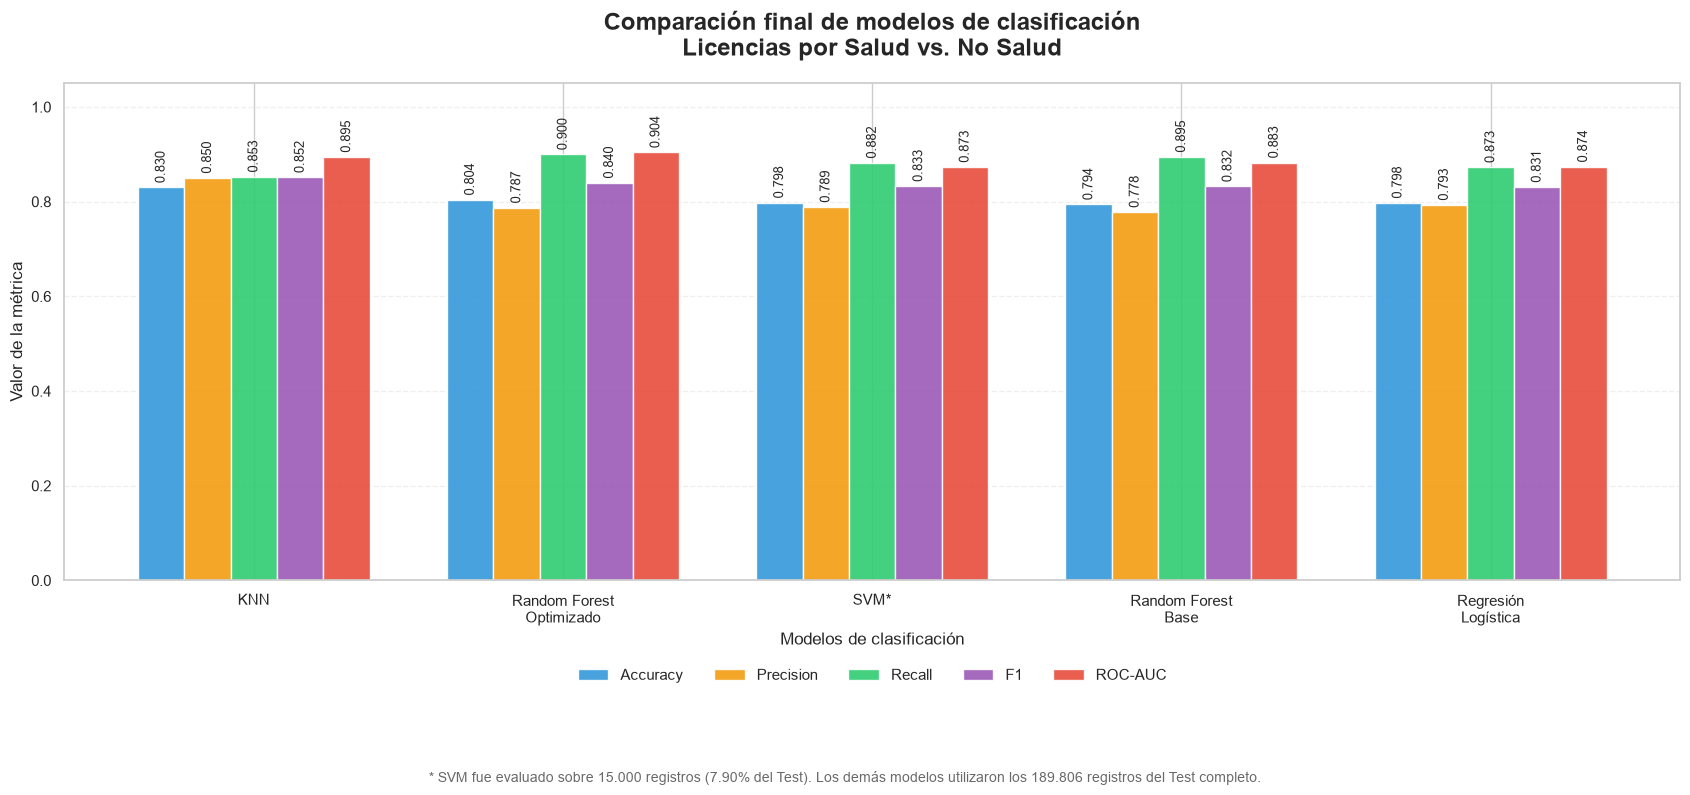

In [51]:

# ==================================================
# COMPARACIÓN FINAL DE MODELOS
# GRÁFICO DE MÉTRICAS DE CLASIFICACIÓN
# ==================================================

import matplotlib.pyplot as plt
import numpy as np

# 1. Preparar los datos

df_grafico_final = df_comparacion_final.copy()

# Utilizar nombres más cortos para el gráfico

nombres_cortos = {
    "Regresión Logística": "Regresión\nLogística",
    "KNN": "KNN",
    "Random Forest Base": "Random Forest\nBase",
    "Random Forest Optimizado": "Random Forest\nOptimizado",
    "SVM": "SVM*"
}

df_grafico_final["Modelo grafico"] = (
    df_grafico_final["Modelo"]
    .map(nombres_cortos)
)

# 2. Definir las métricas y colores

metricas_grafico = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

colores_metricas = [
    "#3498DB",  # Accuracy
    "#F39C12",  # Precision
    "#2ECC71",  # Recall
    "#9B59B6",  # F1
    "#E74C3C"   # ROC-AUC
]

# 3. Configurar posiciones de las barras

x = np.arange(len(df_grafico_final))

ancho = 0.15

fig, ax = plt.subplots(
    figsize=(17, 8)
)

# 4. Crear las barras agrupadas

for i, metrica in enumerate(metricas_grafico):

    desplazamiento = (
        i - (len(metricas_grafico) - 1) / 2
    ) * ancho

    barras = ax.bar(
        x + desplazamiento,
        df_grafico_final[metrica],
        width=ancho,
        label=metrica,
        color=colores_metricas[i],
        alpha=0.90,
        edgecolor="white"
    )

    # Mostrar valores sobre cada barra

    ax.bar_label(
        barras,
        fmt="%.3f",
        padding=3,
        fontsize=9,
        rotation=90
    )

# 5. Configuración visual

ax.set_title(
    "Comparación final de modelos de clasificación\n"
    "Licencias por Salud vs. No Salud",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_ylabel(
    "Valor de la métrica",
    fontsize=12
)

ax.set_xlabel(
    "Modelos de clasificación",
    fontsize=12
)

ax.set_xticks(x)

ax.set_xticklabels(
    df_grafico_final["Modelo grafico"],
    fontsize=11
)

ax.set_ylim(0, 1.05)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

ax.set_axisbelow(True)

# 6. Ubicar la leyenda fuera del área de barras

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=5,
    fontsize=11,
    frameon=False
)

# 7. Agregar aclaración metodológica

fig.text(
    0.5,
    0.015,
    "* SVM fue evaluado sobre 15.000 registros "
    "(7.90% del Test). "
    "Los demás modelos utilizaron los 189.806 "
    "registros del Test completo.",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(
    rect=[0, 0.09, 1, 1]
)

plt.show()


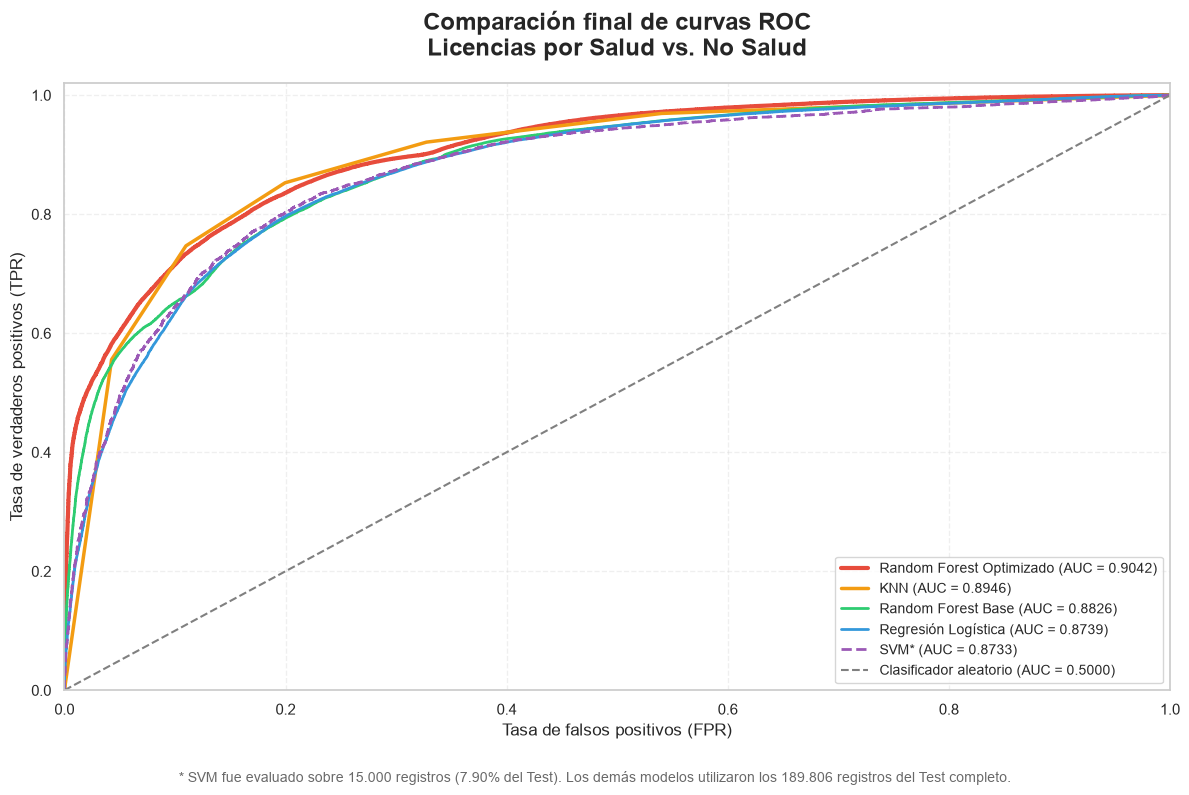


RESULTADOS FINALES ROC-AUC



,Modelo,ROC-AUC,Registros evaluados,% Test utilizado
0,Random Forest Optimizado,0.9042,189806,100.0000
1,KNN,0.8946,189806,100.0000
2,Random Forest Base,0.8826,189806,100.0000
3,Regresión Logística,0.8739,189806,100.0000
4,SVM*,0.8733,15000,7.9028


In [52]:

# ==================================================
# COMPARACIÓN FINAL DE MODELOS
# CURVAS ROC - INCLUYE RANDOM FOREST OPTIMIZADO
# ==================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# 1. Definir modelos, probabilidades y colores

modelos_roc_final = [

    {
        "Modelo": "Regresión Logística",
        "y_real": y_test,
        "y_score": y_prob_logistica,
        "color": "#3498DB",
        "estilo": "-",
        "grosor": 2
    },

    {
        "Modelo": "KNN",
        "y_real": y_test,
        "y_score": y_prob_knn,
        "color": "#F39C12",
        "estilo": "-",
        "grosor": 2.5
    },

    {
        "Modelo": "Random Forest Base",
        "y_real": y_test,
        "y_score": y_prob_rf,
        "color": "#2ECC71",
        "estilo": "-",
        "grosor": 2
    },

    {
        "Modelo": "Random Forest Optimizado",
        "y_real": y_test,
        "y_score": y_prob_rf_optimizado,
        "color": "#E74C3C",
        "estilo": "-",
        "grosor": 3
    },

    {
        "Modelo": "SVM*",
        "y_real": y_test_svm,
        "y_score": y_score_svm,
        "color": "#9B59B6",
        "estilo": "--",
        "grosor": 2
    }

]

# 2. Calcular las curvas ROC y sus AUC

resultados_roc_final = []

for modelo in modelos_roc_final:

    y_real = modelo["y_real"]
    y_score = modelo["y_score"]

    # Verificar dimensiones

    assert len(y_real) == len(y_score)

    # Calcular curva ROC

    fpr, tpr, umbrales = roc_curve(
        y_real,
        y_score,
        pos_label=1
    )

    # Calcular área bajo la curva

    auc_modelo = roc_auc_score(
        y_real,
        y_score
    )

    resultados_roc_final.append({

        "Modelo": modelo["Modelo"],
        "FPR": fpr,
        "TPR": tpr,
        "ROC-AUC": auc_modelo,
        "Registros evaluados": len(y_real),
        "color": modelo["color"],
        "estilo": modelo["estilo"],
        "grosor": modelo["grosor"]

    })

# 3. Ordenar las curvas según ROC-AUC

resultados_roc_final = sorted(
    resultados_roc_final,
    key=lambda modelo: modelo["ROC-AUC"],
    reverse=True
)

# 4. Crear gráfico ROC

fig, ax = plt.subplots(
    figsize=(12, 8)
)

for modelo in resultados_roc_final:

    ax.plot(
        modelo["FPR"],
        modelo["TPR"],
        color=modelo["color"],
        linestyle=modelo["estilo"],
        linewidth=modelo["grosor"],
        label=(
            f"{modelo['Modelo']} "
            f"(AUC = {modelo['ROC-AUC']:.4f})"
        )
    )

# 5. Línea de referencia aleatoria

ax.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Clasificador aleatorio (AUC = 0.5000)"
)

# 6. Configuración visual

ax.set_title(
    "Comparación final de curvas ROC\n"
    "Licencias por Salud vs. No Salud",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Tasa de falsos positivos (FPR)",
    fontsize=12
)

ax.set_ylabel(
    "Tasa de verdaderos positivos (TPR)",
    fontsize=12
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.grid(
    linestyle="--",
    alpha=0.30
)

ax.legend(
    loc="lower right",
    fontsize=10,
    frameon=True
)

# 7. Aclaración metodológica

fig.text(
    0.5,
    0.015,
    "* SVM fue evaluado sobre 15.000 registros "
    "(7.90% del Test). "
    "Los demás modelos utilizaron los 189.806 "
    "registros del Test completo.",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)

plt.show()

# 8. Tabla final de ROC-AUC

df_roc_final = pd.DataFrame([

    {
        "Modelo": modelo["Modelo"],
        "ROC-AUC": modelo["ROC-AUC"],
        "Registros evaluados": (
            modelo["Registros evaluados"]
        ),
        "% Test utilizado": (
            modelo["Registros evaluados"]
            / len(y_test) * 100
        )
    }

    for modelo in resultados_roc_final

])

print("\nRESULTADOS FINALES ROC-AUC\n")

display(df_roc_final.round(4))


<span style="font-size: 20px; font-weight: bold; color: #003366;">Conclusiones Finales: Modelo Predictivo de Ausentismo Laboral</span>

# Conclusiones Finales: Modelo Predictivo de Ausentismo Laboral

## 1. Resumen Ejecutivo y Alcance del Proyecto

El presente proyecto tuvo como objetivo principal desarrollar un modelo de aprendizaje automático (Machine Learning) capaz de clasificar y predecir las solicitudes de ausencia en la Administración Pública de una provincia argentina, discriminando entre licencias por motivos de salud y solicitudes por razones particulares o permisos.

Utilizando un volumen de datos superior a 900.000 registros, el estudio permitió estructurar un pipeline analítico robusto que aporta valor operativo y control de gestión al área de Recursos Humanos.

El análisis se desarrolló sobre un conjunto definitivo de **949.027 registros**, correspondientes a los años 2024 y 2025, integrando técnicas de análisis exploratorio, ingeniería de características, aprendizaje no supervisado y aprendizaje supervisado.

---

## 2. Hallazgos Metodológicos e Ingeniería de Características

A lo largo del desarrollo iterativo del proyecto, se identificaron y subsanaron desafíos metodológicos clave:

* **Limpieza y Consistencia Temporal del Dataset:** Se delimitó el período de estudio a los años 2024 y 2025, obteniendo un conjunto definitivo de 949.027 registros. Se excluyeron 11 observaciones correspondientes a años fuera del período analizado, garantizando una mayor consistencia temporal en el proceso de modelado.

* **Prevención de Fuga de Datos (Data Leakage):** Se excluyeron variables administrativas normativas que definían por regla directa el tipo de ausencia, como el código y la descripción del artículo, la cantidad de días permitidos por mes y por año, así como la duración y la fecha de finalización de la licencia. De esta manera, el entrenamiento se concentró en el perfil demográfico, laboral y temporal de los agentes, evitando incorporar información que pudiera anticipar artificialmente la variable objetivo.

* **Ingeniería de Características y Preprocesamiento:** Se seleccionaron 11 variables predictoras, diferenciando entre variables categóricas, numéricas y binarias. Se aplicaron técnicas de One-Hot Encoding y StandardScaler, obteniendo una matriz de 696 características transformadas. El preprocesamiento fue ajustado exclusivamente sobre el conjunto de entrenamiento, evitando incorporar información del conjunto de prueba.

* **Incorporación de la Estacionalidad:** Se incorporaron variables temporales relacionadas con el mes de inicio, día de la semana, feriados, días adyacentes a feriados y estacionalidad invernal (es_invierno_num). Estas características permitieron representar particularidades del calendario laboral y del contexto regional, considerando las condiciones climáticas de la provincia. Sin embargo, el análisis de importancia de variables de Random Forest Base evidenció que las características laborales y administrativas tuvieron un peso predictivo considerablemente superior al de las variables estacionales.

* **Estudio de Ablación de la Remuneración Mensual:** Se evaluó el aporte de esta variable mediante dos modelos de Regresión Logística, entrenados con y sin remuneración mensual. Su incorporación permitió incrementar el ROC-AUC de 0,8495 a 0,8742, manteniendo un F1-Score prácticamente constante. A partir de estos resultados, se decidió conservar la remuneración mensual dentro del conjunto definitivo de variables predictoras, considerando necesario verificar su disponibilidad al momento de realizar futuras predicciones.

* **Aprendizaje No Supervisado:** Durante el análisis exploratorio se aplicaron técnicas de K-Means, DBSCAN y PCA para identificar perfiles de dependencias según la duración media de las licencias, la antigüedad promedio de los agentes y el volumen de registros. K-Means permitió identificar cuatro grupos diferenciados, mientras que DBSCAN identificó dos clusters y once dependencias consideradas ruido. PCA permitió representar las tres variables originales mediante dos componentes principales, conservando el 81,80% de la varianza total. Estos resultados complementaron la comprensión del dataset antes de avanzar hacia el aprendizaje supervisado.

* **Optimización de Hiperparámetros:** Se realizó un proceso de búsqueda y evaluación de diferentes configuraciones de Random Forest utilizando un conjunto de validación independiente del conjunto de prueba. La configuración seleccionada permitió mejorar el rendimiento del modelo base, particularmente su capacidad de discriminación entre licencias por Salud y No Salud.

---

## 3. Evaluación Comparativa y Rendimiento de los Modelos

Se evaluaron cuatro paradigmas diferentes de clasificación (Regresión Logística, KNN, SVM y Random Forest), incorporando además una versión optimizada de Random Forest. El desempeño de los modelos se analizó mediante las métricas Accuracy, Precision, Recall, F1-Score y ROC-AUC.

### Resultados Finales de los Modelos

| Modelo | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Regresión Logística | 0,7976 | 0,7933 | 0,8728 | 0,8311 | 0,8739 |
| KNN | **0,8303** | **0,8503** | 0,8527 | **0,8515** | 0,8946 |
| SVM* | 0,7981 | 0,7889 | 0,8821 | 0,8329 | 0,8733 |
| Random Forest Base | 0,7943 | 0,7781 | 0,8947 | 0,8323 | 0,8826 |
| Random Forest Optimizado | 0,8042 | 0,7874 | **0,8999** | 0,8399 | **0,9042** |

> **Nota metodológica:** SVM fue evaluado sobre una muestra estratificada de 15.000 registros, equivalente al 7,90% del conjunto de Test. Los demás modelos fueron evaluados sobre los 189.806 registros del conjunto de prueba completo. Por este motivo, los resultados de SVM deben interpretarse como una referencia exploratoria y no como una comparación estrictamente equivalente.

### Regresión Logística (Modelo Baseline)

Actuó como modelo lineal base (baseline), alcanzando una Accuracy del 79,76%, una Precision del 79,33%, un Recall del 87,28%, un F1-Score de 0,8311 y un ROC-AUC de 0,8739.

Sus resultados permitieron establecer una referencia sólida para evaluar el desempeño de los modelos posteriores. Si bien presentó una capacidad de clasificación competitiva, los modelos no lineales lograron mejoras en diferentes dimensiones del rendimiento predictivo.

### K-Nearest Neighbors (KNN)

El modelo KNN (k=5) demostró un desempeño sólido y competitivo, consolidándose como el clasificador con mejores resultados en tres de las cinco métricas evaluadas:

* **Accuracy: 83,03%.**
* **Precision: 85,03%.**
* **Recall: 85,27%.**
* **F1-Score: 0,8515.**
* **ROC-AUC: 0,8946.**

Estos resultados evidencian la capacidad del algoritmo para identificar patrones similares entre los registros y clasificar correctamente las solicitudes de ausencia.

Su principal ventaja radica en la calidad de las clasificaciones obtenidas, particularmente en la reducción de falsos positivos y en el equilibrio entre Precision y Recall.

Sin embargo, su principal limitación se encuentra en el elevado costo computacional durante la etapa de predicción. Al requerir la búsqueda de vecinos dentro del conjunto de entrenamiento, la ejecución sobre los 189.806 registros del conjunto de prueba demandó **38 minutos y 44,63 segundos**, incluyendo las operaciones de entrenamiento, predicción y evaluación.

Esta característica limita su escalabilidad ante grandes volúmenes de información y escenarios que requieren respuestas frecuentes o rápidas.

### Support Vector Machine (SVM)

El modelo SVM con kernel RBF alcanzó una Accuracy del 79,81%, una Precision del 78,89%, un Recall del 88,21%, un F1-Score de 0,8329 y un ROC-AUC de 0,8733.

Estos resultados demostraron que los enfoques basados en márgenes óptimos presentan una capacidad competitiva para adaptarse a la estructura de los datos.

No obstante, debido a su elevado costo computacional, el modelo fue entrenado y evaluado utilizando muestras estratificadas de 15.000 registros. Esta limitación impide realizar una comparación estrictamente equivalente con los modelos evaluados sobre el conjunto de prueba completo.

### Random Forest Base

El modelo Random Forest Base permitió evaluar el rendimiento de un enfoque de aprendizaje por ensamble (Ensemble Learning), basado en la combinación de múltiples árboles de decisión.

Alcanzó una Accuracy del 79,43%, una Precision del 77,81%, un Recall del 89,47%, un F1-Score de 0,8323 y un ROC-AUC de 0,8826.

Su elevado Recall evidenció una buena capacidad para identificar licencias correspondientes a la clase Salud, aunque presentó una menor Precision respecto de KNN.

Estos resultados constituyeron el punto de partida para el proceso de optimización de hiperparámetros.

### Random Forest Optimizado (Modelo Seleccionado)

La optimización de hiperparámetros permitió mejorar el rendimiento de Random Forest respecto de su configuración inicial, alcanzando los siguientes resultados:

* **Accuracy: 80,42%.**
* **Precision: 78,74%.**
* **Recall: 89,99%.**
* **F1-Score: 0,8399.**
* **ROC-AUC: 0,9042.**

El modelo optimizado obtuvo el mayor Recall y ROC-AUC entre todos los clasificadores evaluados.

El incremento del ROC-AUC, desde 0,8826 en el modelo base hasta 0,9042 en el modelo optimizado, representa una mejora en la capacidad de discriminación entre las clases Salud y No Salud.

Su elevado Recall permite identificar aproximadamente nueve de cada diez licencias reales por motivos de salud, reduciendo la proporción de falsos negativos.

Además, Random Forest presenta ventajas operativas relacionadas con su arquitectura de árboles de decisión. Una vez entrenado, puede generar predicciones sin realizar búsquedas de vecinos sobre la totalidad del conjunto de entrenamiento, lo que favorece su utilización sobre grandes volúmenes de datos.

Como contrapartida, su Precision es inferior a la obtenida por KNN, lo que implica una mayor proporción de falsos positivos entre los registros clasificados como Salud.

### Comparación de Curvas ROC y Capacidad de Discriminación

El análisis comparativo de las curvas ROC permitió evaluar la capacidad de los modelos para distinguir entre las clases Salud y No Salud considerando diferentes umbrales de clasificación.

Random Forest Optimizado obtuvo el mayor ROC-AUC, con un valor de **0,9042**, seguido por KNN con **0,8946** y Random Forest Base con **0,8826**.

Regresión Logística y SVM obtuvieron valores de 0,8739 y 0,8733, respectivamente.

Estos resultados evidencian que todos los modelos presentan una capacidad de discriminación superior a la de un clasificador aleatorio, destacándose Random Forest Optimizado por su rendimiento global a través de diferentes umbrales de decisión.

### Selección del Modelo Final

A partir del análisis comparativo, se identificaron dos alternativas destacadas:

* **KNN:** constituye la mejor opción cuando se prioriza el rendimiento de clasificación, dado que obtuvo la mayor Accuracy, Precision y F1-Score. Su principal limitación es el elevado costo computacional durante la predicción.

* **Random Forest Optimizado:** constituye la alternativa recomendada para una futura implementación operativa, debido a su mayor Recall, su superior capacidad de discriminación medida mediante ROC-AUC y las ventajas computacionales esperadas durante la generación de predicciones.

En consecuencia, considerando el volumen de información analizado, la necesidad de identificar correctamente las licencias por salud y la conveniencia de contar con un modelo escalable, se selecciona **Random Forest Optimizado como modelo final del proyecto**.

Esta elección no implica que Random Forest supere a KNN en todas las métricas, sino que representa un equilibrio favorable entre capacidad predictiva, sensibilidad y viabilidad operativa.

La ventaja en términos de eficiencia computacional deberá confirmarse mediante mediciones de tiempos de inferencia realizadas bajo condiciones equivalentes.

---

## 4. Implicancias Prácticas y Valor Operativo para RRHH

Desde una perspectiva de gestión y control bajo normativas de calidad (como ISO 9001), los resultados obtenidos permiten identificar diferentes oportunidades de aplicación:

* **Minimización de Falsas Alarmas:** KNN alcanzó una Precision del 85,03%, lo que significa que aproximadamente 85 de cada 100 registros clasificados como Salud correspondieron efectivamente a dicha categoría. Este resultado lo posiciona como una alternativa favorable cuando se busca reducir las clasificaciones incorrectas y las revisiones manuales innecesarias.

* **Capacidad de Detección de Licencias por Salud:** Random Forest Optimizado obtuvo un Recall del 89,99%, identificando aproximadamente 90 de cada 100 licencias reales por motivos de salud. Esta capacidad resulta especialmente relevante cuando se busca minimizar los casos que podrían pasar inadvertidos en un proceso de clasificación automatizada.

* **Capacidad de Discriminación y Flexibilidad Operativa:** El ROC-AUC de 0,9042 obtenido por Random Forest Optimizado indica una elevada capacidad para distinguir entre licencias por Salud y No Salud. Esto permitiría evaluar diferentes umbrales de clasificación según las necesidades operativas del organismo, equilibrando la detección de casos con la reducción de falsos positivos.

* **Soporte para la Toma de Decisiones:** El modelo desarrollado constituye una base para la futura implementación de herramientas de apoyo a Recursos Humanos, permitiendo analizar la composición de las licencias, identificar patrones y contribuir a la planificación operativa del personal en las distintas dependencias.

* **Eficiencia Computacional y Escalabilidad:** La selección de Random Forest Optimizado busca favorecer la aplicación del modelo sobre grandes volúmenes de registros, considerando las limitaciones de procesamiento observadas en KNN. Esta característica adquiere relevancia ante una eventual integración con sistemas administrativos y procesos de actualización periódica de información.

* **Caracterización de las Dependencias:** Los resultados del aprendizaje no supervisado permitieron identificar perfiles diferenciados de dependencias según la duración media de las licencias, la antigüedad de los agentes y el volumen de registros. Esta información complementa el análisis predictivo y puede contribuir a una mejor comprensión de las características particulares de cada organismo.

### Limitaciones y Consideraciones para una Implementación Futura

Si bien los resultados obtenidos evidencian el potencial de las técnicas aplicadas, es necesario considerar las siguientes limitaciones:

* El modelo desarrollado clasifica el motivo de una ausencia cuyo inicio es conocido. No predice directamente si un agente se ausentará en una fecha futura ni la duración de esa ausencia.

* La división del dataset en conjuntos de entrenamiento y prueba se realizó de manera aleatoria y estratificada. Para evaluar la capacidad de generalización hacia períodos futuros, sería recomendable realizar una validación temporal, utilizando un año para el entrenamiento y otro para la evaluación.

* La existencia de múltiples registros correspondientes a un mismo agente puede generar dependencia entre las observaciones. En futuras etapas, sería conveniente evaluar una separación por legajo para analizar el desempeño del modelo sobre agentes no observados durante el entrenamiento.

* La remuneración mensual presentó un aporte favorable al rendimiento predictivo. Sin embargo, es necesario verificar el origen de los valores negativos detectados durante el análisis exploratorio y confirmar que la información salarial se encuentre disponible al momento de realizar la predicción.

* La cantidad de registros de ausencia por dependencia no equivale a una tasa de ausentismo, debido a que no se dispone de información sobre la dotación total de empleados de cada organismo.

* Las predicciones del modelo deberán utilizarse como una herramienta de apoyo a la gestión y no como fundamento exclusivo para decisiones individuales sobre el personal.

### Conclusión General del Proyecto

En conclusión, el presente proyecto permitió desarrollar un proceso integral de Data Science y Machine Learning, abarcando desde la comprensión y preparación de los datos hasta la evaluación, comparación y selección de modelos predictivos.

Los resultados obtenidos demostraron que las características laborales, demográficas y temporales de los agentes contienen información relevante para la clasificación de las licencias por Salud y No Salud.

KNN se destacó por alcanzar los mejores resultados en Accuracy, Precision y F1-Score, mientras que Random Forest Optimizado presentó la mayor capacidad de detección y discriminación entre las clases analizadas.

La selección de **Random Forest Optimizado como modelo final** representa una decisión fundamentada en su elevado Recall del 89,99%, su ROC-AUC de 0,9042 y su potencial de escalabilidad para el procesamiento de grandes volúmenes de información.

De esta manera, el proyecto demuestra el potencial de las técnicas de Data Science y Machine Learning para transformar registros administrativos de ausentismo en información útil para la gestión pública, estableciendo una base metodológica para futuros desarrollos predictivos, mejoras en los procesos de Recursos Humanos y herramientas de apoyo a la toma de decisiones.

